# Quality Control and Read Alignment of *Hypolimnas misippus* Low-Coverage Sequencing Data

**Course:** Genome-Wide Association Studies (GWAS) for Evolutionary Biology  
**Instructor:** Nikolay Oskolkov  
**Platform:** Google Colab  
**Organism:** *Hypolimnas misippus* (the Diadem or Danaid eggfly), a pantropical butterfly  
**Data and biology from:** Orteu et al. (2024) *Transposable element insertions are associated with Batesian mimicry in the pantropical butterfly Hypolimnas misippus.* Molecular Biology and Evolution 41(3): msae041.

---

In this notebook we start from a folder of raw FASTQ files (`smallfastqs_Hypolimnas_misippus`) and finish with **sorted, indexed BAM files** and a **sample sheet linking every BAM to its wing morph**. These are the inputs that the next notebook will use to run an association test between the two morphs.

We will:

1. Install **Conda** (via `condacolab`) and the tools **FastQC, MultiQC, fastp, seqkit, BWA, SAMtools and BEDTools** from Bioconda.
2. Mount **Google Drive** and locate the input FASTQ files, the morph annotation, and the ENA metadata table.
3. Build a **sample sheet** that links every FASTQ file to a sample ID (`CAMxxxxxx`) and a morph (`m` or `i`).
4. Run **FastQC** and **MultiQC** on the raw reads.
5. Remove adapters and low-quality bases with **fastp**.
6. Re-run **FastQC** and **MultiQC** on the trimmed reads to confirm the effect.
7. **Download and index the *H. misippus* reference genome on the fly** (no manual download needed).
8. Align every sample with **BWA-MEM**, producing sorted and indexed BAM files.
9. Evaluate the alignments (mapping rate, depth, sex-chromosome check) and test whether the two morphs differ **technically**, which would be a confounder in a GWAS.
10. Look at the **M locus** on chromosome 26 as a positive control.

> **How to use this notebook.** Run the cells from top to bottom. The very first code cell restarts the Colab runtime on purpose. Every long loop is **resumable**: if Colab disconnects, reconnect, re-run the setup cells, and the loops will skip samples that are already finished.

## 0. Background: why this dataset, and what are we trying to do?

### 0.1 The butterfly and its mimicry

*Hypolimnas misippus* is a **Batesian mimic**: a palatable species whose females resemble a toxic, unpalatable model species, so that predators that have learned to avoid the model also avoid the mimic. The model here is the African Queen butterfly, *Danaus chrysippus*, which comes in several geographic colour forms.

* **Males** of *H. misippus* are not mimetic: they are black with white, blue-fringed spots.
* **Females** are mimetic and **polymorphic**: different females resemble different forms of *D. chrysippus*.

### 0.2 The genetics: the M locus

Female wing colour is controlled mainly by two loci of large effect, **M** (forewing pattern) and **A** (hindwing pattern). In this course we focus on the forewing locus **M**:

| Genotype | Forewing phenotype | Morph name |
|---|---|---|
| `M-` (one or two copies of the dominant allele **M**) | black forewing tip with a white band | *misippus* |
| `mm` (homozygous for the recessive allele **m**) | orange forewing (or intermediate when the dominant hindwing allele **A** is also present) | *inaria* (and *immima*) |

Orteu et al. (2024) used a genome-wide association study (GWAS) to confirm that M maps to a region of about 12 kb on **chromosome 26** (6,731,000 to 6,743,400 bp in the reference assembly). Looking closer, they found that the **dominant M allele carries two large transposable-element (TE) insertions** (2.4 kb and 4.3 kb) in an intron of a gene of unknown function (*g1743*), close to the genes *pink* and *Sox5/6*. The recessive *m* allele, which produces the ancestral-looking phenotype, lacks them. The reference genome was assembled from an **M homozygote**, so it contains the TE insertions, and reads from `mm` individuals **cannot map** to those tracts. We will use this fact as a **positive control** in Section 12.

### 0.3 The data

* **Samples:** 332 wild-caught *H. misippus* females from across Africa (the paper analyses 331 of them in the GWAS).
* **Phenotypes:** 275 *misippus* (`M-`) and 57 *inaria/immima* (`mm`) females.
* **Sequencing:** *haplotagging*, a **linked-read** technique in which a Tn5 transposase loaded on beads fragments long DNA molecules and attaches a barcode so that reads from the same molecule can be identified. Average coverage was low, about **0.81x per individual** in the full dataset. The raw data are in the European Nucleotide Archive (ENA) under project **PRJEB64669**.
* **What we use here:** a *small* FASTQ file per sample (folder `smallfastqs_Hypolimnas_misippus`), small enough to run in a free Colab session. The molecule barcodes are not used in this notebook.
* **Layout:** in the ENA metadata table you provided (`ENA_runs_full.tsv`) all annotated samples are listed as `SINGLE` layout, so we treat the reads as **single-end**.

### 0.4 Caution: the letters `m` and `i` in the annotation file

The annotation file `Hypolimnas_misippus_CAMID_morph.txt` has a column `morph` with the values **`m`** and **`i`**:

* **`m` = *misippus* morph** = genotype **`M-`** (dominant allele present). 275 samples.
* **`i` = *inaria* (and *immima*) morph** = genotype **`mm`** (recessive homozygote). 57 samples.

Be careful not to confuse the **morph label `m`** (a *phenotype*, which carries the *dominant* allele) with the **recessive allele `m`**. In this notebook, `m` and `i` always mean the **phenotype labels** from the annotation file.

### 0.5 Why does QC and alignment matter for a GWAS?

A GWAS tests, at every variant, whether genotype and phenotype are associated. The statistical test can only be as good as the genotypes, and the genotypes can only be as good as the alignments. Three things matter in particular:

1. **Systematic technical differences between cases and controls create false associations.** If the `i` samples were sequenced deeper, mapped better, or had a different adapter content than the `m` samples, a technical signal could masquerade as a genetic one. We will therefore **compare QC metrics between the two morphs** at every stage.
2. **Low coverage means uncertain genotypes.** At < 1x depth most sites are covered by 0 or 1 reads, so genotypes cannot be called confidently. Methods designed for low coverage (genotype likelihoods, or imputation) are needed downstream. Good alignments are a prerequisite for those.
3. **Reference choice matters.** The reference should be of the same species, ideally chromosome-level, so that reads map uniquely and the coordinates are meaningful. The paper aligned to **HypMis_v2**, and so will we.

### 0.6 The pipeline at a glance

| Step | Tool | Input | Output | Why |
|---|---|---|---|---|
| Read summary | `seqkit stats` | FASTQ | table of read counts, lengths, quality | quick sanity check of every file |
| Raw QC | `FastQC`, `MultiQC` | FASTQ | HTML reports | find problems before they propagate |
| Trimming | `fastp` | FASTQ | trimmed FASTQ + JSON/HTML | remove adapters and poor bases |
| Trimmed QC | `FastQC`, `MultiQC` | trimmed FASTQ | HTML reports | confirm trimming worked |
| Reference | NCBI + `bwa index`, `samtools faidx` | FASTA | index files | prepare the reference for fast mapping |
| Alignment | `bwa mem`, `samtools sort/index` | FASTQ + reference | sorted BAM + BAI | place every read on the genome |
| Alignment QC | `samtools stats/flagstat/idxstats` | BAM | tables, plots | mapping rate, depth, sex check |
| Positive control | `samtools depth` | BAM | coverage plot | see the M-locus TE insertions |

## 1. Install Conda in Google Colab

Google Colab does not ship with Conda. The `condacolab` package installs a lightweight **Miniforge** (Conda plus the fast `mamba` solver) directly into the running notebook.

> ⚠️ **Important:** After this cell finishes, the Colab kernel **restarts automatically**. This is expected. Once the restart is done, simply continue with the next cell. You do **not** need to re-run this cell.

In [2]:
# Install Conda (Miniforge) inside Google Colab. The kernel restarts automatically afterwards.
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:15
🔁 Restarting kernel...


## 2. Install FastQC, MultiQC, fastp, seqkit, BWA, SAMtools and BEDTools

All of these tools are available from **Bioconda**, a Conda channel dedicated to bioinformatics software. Bioconda packages need the **conda-forge** channel too, so we list both (`-c conda-forge -c bioconda`). We use `mamba`, a much faster dependency solver than classic `conda`.

| Tool | Purpose |
|---|---|
| **FastQC** | Per-sample quality report (per-base quality, GC content, adapters, duplication) |
| **MultiQC** | Combines hundreds of FastQC, fastp and SAMtools reports into one page |
| **fastp** | Fast adapter and quality trimming that also writes a JSON report |
| **seqkit** | Very fast summary statistics and manipulation of FASTQ and FASTA files |
| **BWA** | Burrows-Wheeler Aligner; `bwa mem` aligns reads to the reference |
| **SAMtools** | Sort, index, filter and summarise alignment files (SAM, BAM, CRAM) |
| **BEDTools** | Genomic interval arithmetic (used downstream) |

The installation takes a few minutes.

In [1]:
%%bash
mamba install -y -q -c conda-forge -c bioconda fastqc multiqc fastp seqkit bwa samtools bedtools

warning  libmamba [numpy-2.5.4-py313hb5f73ae_0] The following files were already present in the environment:
    - bin/f2py
    - bin/numpy-config
warning  libmamba [natsort-8.4.0-pyhcf101f3_2] The following files were already present in the environment:
    - bin/natsort
warning  libmamba [python-dotenv-1.2.4-pyh5ded981_0] The following files were already present in the environment:
    - bin/dotenv
warning  libmamba [pygments-2.21.0-pyhcf101f3_0] The following files were already present in the environment:
    - bin/pygmentize
warning  libmamba [plotly-6.9.0-pyhd8ed1ab_0] The following files were already present in the environment:
    - share/jupyter/labextensions/jupyterlab-plotly/package.json
    - share/jupyter/labextensions/jupyterlab-plotly/static/style.js
    - share/jupyter/labextensions/jupyterlab-plotly/static/third-party-licenses.json
warning  libmamba [markdown-it-py-4.2.0-pyhd8ed1ab_0] The following files were already present in the environment:
    - bin/markdown-it
war

### 2.1 Verify the installation

Let us confirm that every tool is on the `PATH` and print its version. Recording versions is good practice for reproducibility: the exact version should be reported in the Methods section of any paper that uses this pipeline.

In [2]:
%%bash
echo "FastQC:   $(fastqc --version)"
echo "MultiQC:  $(multiqc --version)"
echo "fastp:    $(fastp --version 2>&1)"
echo "seqkit:   $(seqkit version)"
echo "BWA:      $(bwa 2>&1 | grep -i '^Version')"
echo "SAMtools: $(samtools --version | head -n 1)"
echo "BEDTools: $(bedtools --version)"
echo
echo "CPU cores available: $(nproc)"
echo "Free memory:"; free -h | head -n 2
echo "Free disk on /content:"; df -h /content | tail -n 1

FastQC:   [0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
FastQC v0.13.0
MultiQC:  multiqc, version 1.35
fastp:    fastp 1.4.0
seqkit:   seqkit v2.14.0
BWA:      Version: 0.7.19-r1273
SAMtools: samtools 1.25
BEDTools: bedtools v2.31.1

CPU cores available: 2
Free memory:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.2Gi       1.1Gi       2.7Mi        10Gi        11Gi
Free disk on /content:
overlay         108G  3.8G  104G   4% /


## 3. Mount Google Drive and Configure the Project

Colab's local disk is wiped when the session ends, but **Google Drive persists**. We therefore store inputs and all important outputs (trimmed reads, reference index, BAM files, QC reports) on Drive, while temporary files go to the fast local disk.

Running the cell below opens an authorisation dialog. Grant access to your Drive and return to the notebook.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 3.1 Locate the input files and define the project layout

The next cell:

* looks for the folder **`smallfastqs_Hypolimnas_misippus`** anywhere in your Drive (up to six folder levels deep) and uses its **parent folder** as the *project folder*. All output folders are created next to it;
* looks for the two metadata files, `Hypolimnas_misippus_CAMID_morph.txt` (required) and `ENA_runs_full.tsv` (optional but recommended), first in the project folder and then anywhere in Drive;
* defines the **trimming parameters** that we will use later.

If the automatic search picks the wrong folder, set `FASTQ_DIR_OVERRIDE` manually (an example is given in the comment).

In [5]:
import os, re, json, gzip, glob, shutil, subprocess, io, urllib.request, urllib.parse
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---------------------------------------------------------------- where is the data?
DRIVE_ROOT = Path("/content/drive/MyDrive/GWAS")
FASTQ_FOLDER_NAME = "smallfastqs_Hypolimnas_misippus"

# If the automatic search fails or picks the wrong folder, set the path here, e.g.
# FASTQ_DIR_OVERRIDE = "/content/drive/MyDrive/GWAS_course/smallfastqs_Hypolimnas_misippus"
FASTQ_DIR_OVERRIDE = None

def find_on_drive(name, kind, maxdepth=6):
    # Search Google Drive for a folder (kind='d') or file (kind='f') with an exact name.
    res = subprocess.run(["find", str(DRIVE_ROOT), "-maxdepth", str(maxdepth),
                          "-type", kind, "-name", name],
                         capture_output=True, text=True)
    return [Path(p) for p in res.stdout.splitlines() if p.strip()]

if FASTQ_DIR_OVERRIDE:
    FASTQ_DIR = Path(FASTQ_DIR_OVERRIDE)
else:
    hits = find_on_drive(FASTQ_FOLDER_NAME, "d")
    assert hits, (f"Could not find a folder called '{FASTQ_FOLDER_NAME}' in your Google Drive. "
                  "Check the name or set FASTQ_DIR_OVERRIDE above.")
    if len(hits) > 1:
        print("WARNING: several matching folders found, using the first one:")
        for h in hits: print("   ", h)
    FASTQ_DIR = hits[0]
assert FASTQ_DIR.is_dir(), f"{FASTQ_DIR} is not a directory"

PROJECT_DIR = FASTQ_DIR.parent

def locate_file(name):
    p = PROJECT_DIR / name
    if p.exists():
        return p
    hits = find_on_drive(name, "f")
    return hits[0] if hits else None

MORPH_FILE = locate_file("Hypolimnas_misippus_CAMID_morph.txt")
ENA_FILE   = locate_file("ENA_runs_full.tsv")
assert MORPH_FILE is not None, "Hypolimnas_misippus_CAMID_morph.txt not found: upload it to the project folder."

# ---------------------------------------------------------------- output folders (on Drive = persistent)
DIRS = {
    "qc_raw":  PROJECT_DIR / "QC_before_adapter_removal",
    "trimmed": PROJECT_DIR / "trimmed_fastqs",
    "qc_trim": PROJECT_DIR / "QC_after_adapter_removal",
    "ref":     PROJECT_DIR / "reference_HypMis_v2",
    "bams":    PROJECT_DIR / "bams",
    "qc_aln":  PROJECT_DIR / "QC_alignment",
    "logs":    PROJECT_DIR / "logs",
}
# ---------------------------------------------------------------- scratch space (local disk = fast, temporary)
LINK_DIR = Path("/content/work/fastq_by_sample")   # symlinks named <sampleID>.fastq.gz
SCRATCH  = Path("/content/work/scratch")
SAMPLE_SHEET = PROJECT_DIR / "sample_sheet.tsv"

for d in list(DIRS.values()) + [LINK_DIR, SCRATCH]:
    d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- analysis parameters
THREADS = os.cpu_count() or 2
MIN_QUAL = 20          # fastp: a base with Phred quality >= this counts as 'qualified'
MAX_UNQUAL_PCT = 30    # fastp: discard a read if more than this % of its bases are unqualified
MIN_LEN = 50           # fastp: discard reads shorter than this after trimming
DOWNLOAD_REPORTS = False   # set to True to download the MultiQC HTML reports to your computer

# ---------------------------------------------------------------- make everything visible to %%bash cells
ENV = {
    "FASTQ_DIR": FASTQ_DIR, "PROJECT_DIR": PROJECT_DIR, "LINK_DIR": LINK_DIR, "SCRATCH": SCRATCH,
    "QC_RAW": DIRS["qc_raw"], "TRIMMED": DIRS["trimmed"], "QC_TRIM": DIRS["qc_trim"],
    "REF_DIR": DIRS["ref"], "BAMS": DIRS["bams"], "QC_ALN": DIRS["qc_aln"], "LOGS": DIRS["logs"],
    "SAMPLE_SHEET": SAMPLE_SHEET, "THREADS": THREADS,
    "MIN_QUAL": MIN_QUAL, "MAX_UNQUAL_PCT": MAX_UNQUAL_PCT, "MIN_LEN": MIN_LEN,
}
for k, v in ENV.items():
    os.environ[k] = str(v)

print("Project folder  :", PROJECT_DIR)
print("FASTQ folder    :", FASTQ_DIR)
print("Morph file      :", MORPH_FILE)
print("ENA table       :", ENA_FILE if ENA_FILE else "not found (only needed if FASTQ files are named by ENA run accession)")
print("CPU threads     :", THREADS)

Project folder  : /content/drive/MyDrive/GWAS
FASTQ folder    : /content/drive/MyDrive/GWAS/smallfastqs_Hypolimnas_misippus
Morph file      : /content/drive/MyDrive/GWAS/Hypolimnas_misippus_CAMID_morph.txt
ENA table       : /content/drive/MyDrive/GWAS/ENA_runs_full.tsv
CPU threads     : 2


### 3.2 A helper to compare the two morphs

Throughout the notebook we want to ask: **do the `m` and `i` samples differ technically?** The function below draws a box-plus-points panel for each metric and runs a **Mann-Whitney U test** (a rank-based test that does not assume normality) between the two groups.

How to read the result: a small *P*-value for a technical metric (for example, depth or mapping rate) does **not** mean something is wrong with the biology. It means that this metric is a **potential confounder** and should be considered, for example by including it as a covariate in the association test or by excluding outlier samples.

In [6]:
from scipy.stats import mannwhitneyu

MORPH_ORDER = ["m", "i"]
MORPH_COLORS = {"m": "#4c72b0", "i": "#dd8452"}

def compare_morphs(df, metrics, ncols=3, logy=(), title=None):
    # df must contain a 'morph' column. metrics = {column: nice label}.
    n = len(metrics)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.8 * ncols, 3.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    out = []
    for ax, (col, label) in zip(axes, metrics.items()):
        sns.boxplot(data=df, x="morph", y=col, order=MORPH_ORDER, hue="morph",
                    palette=MORPH_COLORS, showfliers=False, ax=ax, legend=False)
        sns.stripplot(data=df, x="morph", y=col, order=MORPH_ORDER, color="black",
                      size=2.5, alpha=0.4, ax=ax)
        if col in logy:
            ax.set_yscale("log")
        ax.set_title(label, fontsize=11)
        ax.set_xlabel("")
        a = df.loc[df.morph == "m", col].dropna()
        b = df.loc[df.morph == "i", col].dropna()
        p = mannwhitneyu(a, b).pvalue if (len(a) > 2 and len(b) > 2) else np.nan
        ax.text(0.5, 1.0, f"P = {p:.2g}", transform=ax.transAxes, ha="center", va="bottom", fontsize=8, color="grey")
        out.append(dict(metric=label, median_m=a.median(), median_i=b.median(), mannwhitney_P=p))
    for ax in axes[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(out)

def robust_z(x):
    # Robust z-score using the median and the median absolute deviation (MAD).
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    return (x - med) / (1.4826 * mad) if mad > 0 else np.zeros_like(x)

## 4. Link FASTQ Files, Sample IDs and Morphs: the Sample Sheet

Before touching the reads, we make sure we know **which file belongs to which individual and which morph**. A mistake here silently ruins an association test later (a swapped label turns a true association into noise), so we do this carefully and check the result.

We use three sources of information:

| File | Content |
|---|---|
| `Hypolimnas_misippus_CAMID_morph.txt` | for each sample ID (`CAM035143`, ...) the morph, `m` or `i` |
| `ENA_runs_full.tsv` | the ENA metadata: run accession (`ERR12381503`) → sample alias (`CAM035225`) → library layout, file type |
| the FASTQ file names | should contain either the `CAMxxxxxx` sample ID or an ENA run accession |

The code extracts the sample ID from each file name. If the name contains an ENA **run accession** (`ERR...`) instead of the `CAM` ID, the ENA table translates it. Only samples that have **both** a FASTQ file and a morph label are kept.

For consistent naming in all reports, we then create **symbolic links** called `<sampleID>.fastq.gz` pointing to the real files. FastQC, fastp and MultiQC then label everything with the sample ID.

In [7]:
# ----------------------------------------------------------------- 1) annotation + ENA metadata
morph = pd.read_csv(MORPH_FILE, sep="\t")
morph.columns = ["sampleID", "morph"]
print(f"Annotation file: {len(morph)} samples ->", morph.morph.value_counts().to_dict())

run2cam = {}
if ENA_FILE is not None:
    ena = pd.read_csv(ENA_FILE, sep="\t")
    run2cam = dict(zip(ena.run_accession, ena.sample_alias))
    print(f"ENA table: {len(ena)} runs; library layouts:", ena.library_layout.value_counts().to_dict())
    ann = ena[ena.sample_alias.isin(morph.sampleID)]
    print(f"           annotated samples present in ENA table: {ann.sample_alias.nunique()} of {len(morph)};"
          f" layouts: {ann.library_layout.value_counts().to_dict()}")
    missing_in_ena = sorted(set(morph.sampleID) - set(ena.sample_alias))
    if missing_in_ena:
        print("           annotated but NOT in the ENA table:", missing_in_ena)

# ----------------------------------------------------------------- 2) find the FASTQ files
all_files = sorted(p for p in FASTQ_DIR.iterdir() if p.is_file())
fastq_files = [p for p in all_files if re.search(r"\.(fastq|fq)\.gz$", p.name)]
other_files = [p for p in all_files if p not in fastq_files]
print(f"\nFASTQ folder: {len(fastq_files)} gzipped FASTQ files "
      f"({sum(p.stat().st_size for p in fastq_files)/1e6:.1f} MB in total)")
if other_files:
    print(f"  ignoring {len(other_files)} other files, e.g. {[p.name for p in other_files[:3]]}")
if any(re.search(r"(_R?[12])(_|\.|$)", p.name) for p in fastq_files):
    print("  WARNING: some file names look like paired-end mates (_1/_2 or _R1/_R2). "
          "This notebook assumes single-end reads, as listed in the ENA table.")

# ----------------------------------------------------------------- 3) file name -> sample ID
def sample_from_filename(path):
    name = path.name
    m = re.search(r"(CAM\d{6,})", name)
    if m:
        return m.group(1), "CAM ID in file name"
    m = re.search(r"((?:ERR|SRR|DRR)\d+)", name)
    if m:
        run = m.group(1)
        if run in run2cam:
            return run2cam[run], f"run accession {run} translated with the ENA table"
        return None, f"run accession {run} not found in the ENA table"
    return None, "no CAM ID or run accession in the file name"

records = []
for p in fastq_files:
    sid, how = sample_from_filename(p)
    records.append(dict(sampleID=sid, fastq=str(p), how=how))
files_df = pd.DataFrame(records)

unmatched = files_df[files_df.sampleID.isna()]
dups = files_df[files_df.sampleID.notna() & files_df.sampleID.duplicated(keep=False)]
assert dups.empty, ("Several FASTQ files map to the same sample ID (multiple lanes or paired-end mates?):\n"
                    + dups.sort_values("sampleID").to_string())
if len(unmatched):
    print(f"\n{len(unmatched)} FASTQ files could not be assigned to a sample (they will be ignored):")
    display(unmatched.head(10))

# ----------------------------------------------------------------- 4) merge with the morph annotation
sheet = files_df.dropna(subset=["sampleID"]).merge(morph, on="sampleID", how="inner")
sheet = sheet[["sampleID", "morph", "fastq"]].sort_values("sampleID").reset_index(drop=True)

no_fastq   = sorted(set(morph.sampleID) - set(sheet.sampleID))
no_morph   = sorted(set(files_df.sampleID.dropna()) - set(morph.sampleID))
print("\n================ SAMPLE SHEET SUMMARY ================")
print(f"annotated samples in the morph file          : {len(morph)}")
print(f"FASTQ files assigned to an annotated sample  : {len(sheet)}")
print(f"annotated samples WITHOUT a FASTQ file       : {len(no_fastq)} {no_fastq[:10]}{' ...' if len(no_fastq) > 10 else ''}")
print(f"FASTQ files whose sample has NO morph label  : {len(no_morph)} {no_morph[:10]}{' ...' if len(no_morph) > 10 else ''}")
print("usable samples per morph:", sheet.morph.value_counts().to_dict())
assert len(sheet) > 0, "No usable samples: check the file names in the FASTQ folder."

sheet.to_csv(SAMPLE_SHEET, sep="\t", index=False)
print("\nSample sheet written to", SAMPLE_SHEET)
display(sheet.head())

Annotation file: 332 samples -> {'m': 275, 'i': 57}
ENA table: 555 runs; library layouts: {'SINGLE': 334, 'PAIRED': 221}
           annotated samples present in ENA table: 331 of 332; layouts: {'SINGLE': 331}
           annotated but NOT in the ENA table: ['CAM035321']

FASTQ folder: 20 gzipped FASTQ files (7672.6 MB in total)

================ SAMPLE SHEET SUMMARY ================
annotated samples in the morph file          : 332
FASTQ files assigned to an annotated sample  : 20
annotated samples WITHOUT a FASTQ file       : 312 ['CAM035153', 'CAM035154', 'CAM035156', 'CAM035158', 'CAM035159', 'CAM035160', 'CAM035161', 'CAM035162', 'CAM035164', 'CAM035165'] ...
FASTQ files whose sample has NO morph label  : 0 []
usable samples per morph: {'m': 10, 'i': 10}

Sample sheet written to /content/drive/MyDrive/GWAS/sample_sheet.tsv


,sampleID,morph,fastq
0,CAM035143,m,/content/drive/MyDrive/GWAS/smallfastqs_Hypoli...
1,CAM035144,m,/content/drive/MyDrive/GWAS/smallfastqs_Hypoli...
2,CAM035145,m,/content/drive/MyDrive/GWAS/smallfastqs_Hypoli...
3,CAM035146,m,/content/drive/MyDrive/GWAS/smallfastqs_Hypoli...
4,CAM035147,m,/content/drive/MyDrive/GWAS/smallfastqs_Hypoli...


### 4.1 Create the symbolic links

We create `/content/work/fastq_by_sample/<sampleID>.fastq.gz` for every sample. Links cost no disk space and are re-created in every session (the local disk is temporary; the sample sheet on Drive is the permanent record).

In [8]:
for old in LINK_DIR.glob("*"):
    old.unlink()
for _, r in sheet.iterrows():
    os.symlink(r.fastq, LINK_DIR / f"{r.sampleID}.fastq.gz")
print(f"{len(list(LINK_DIR.glob('*.fastq.gz')))} links created in {LINK_DIR}")
os.environ["SAMPLE_SHEET"] = str(SAMPLE_SHEET)

20 links created in /content/work/fastq_by_sample


## 5. A First Look at the Raw Reads

### 5.1 Anatomy of a FASTQ record

A FASTQ file stores sequencing reads, **four lines per read**:

```
@read_name                    <- 1. header (instrument, run, tile, coordinates, ...)
GATTTGGGGTTCAAAGCAGTATCGATC   <- 2. the DNA sequence
+                             <- 3. separator (may repeat the header)
!''*((((***+))%%%++)(%%%%).1   <- 4. one quality character per base
```

The fourth line encodes the **Phred quality score** *Q* of each base: the probability *P* that the base call is wrong is

$$Q = -10 \log_{10} P \quad\Longleftrightarrow\quad P = 10^{-Q/10}$$

| Phred Q | Error probability | Accuracy |
|---|---|---|
| 10 | 1 in 10 | 90 % |
| 20 | 1 in 100 | 99 % |
| 30 | 1 in 1,000 | 99.9 % |
| 40 | 1 in 10,000 | 99.99 % |

In the file, *Q* is stored as the ASCII character with code *Q* + 33 ("Phred+33", used by all modern Illumina data). The cell below reads the first record of the first file and decodes the first 20 bases.

In [9]:
first_sample = sheet.sampleID.iloc[0]
fq = LINK_DIR / f"{first_sample}.fastq.gz"
with gzip.open(fq, "rt") as fh:
    header, seq, plus, qual = [fh.readline().rstrip("\n") for _ in range(4)]

print("sample :", first_sample)
print("header :", header)
print("length :", len(seq), "bases\n")

phred = [ord(c) - 33 for c in qual]
demo = pd.DataFrame({
    "position": range(1, 21),
    "base": list(seq[:20]),
    "quality_char": list(qual[:20]),
    "ASCII_code": [ord(c) for c in qual[:20]],
    "Phred_Q": phred[:20],
    "P(base is wrong)": [round(10 ** (-q / 10), 5) for q in phred[:20]],
})
display(demo)
print(f"Expected number of errors in this whole read: {sum(10 ** (-q / 10) for q in phred):.2f}")

sample : CAM035143
header : @ST-J00101:184:HH5KFBBXY:8:1121:15838:5939/1
length : 150 bases



,position,base,quality_char,ASCII_code,Phred_Q,P(base is wrong)
0,1,C,A,65,32,0.00063
1,2,T,A,65,32,0.00063
2,3,T,A,65,32,0.00063
3,4,G,F,70,37,0.00020
4,5,T,F,70,37,0.00020
5,6,A,J,74,41,0.00008
6,7,T,J,74,41,0.00008
7,8,A,J,74,41,0.00008
8,9,T,J,74,41,0.00008
9,10,A,J,74,41,0.00008


Expected number of errors in this whole read: 0.01


### 5.2 Summary statistics for all FASTQ files with `seqkit`

`seqkit stats` reads every file and reports, per file: the number of reads (`num_seqs`), total bases (`sum_len`), minimum, average and maximum read length, the fraction of bases with quality ≥ Q20 and ≥ Q30, the average quality, and the GC content. This is the fastest way to spot a broken, empty, or unusually small file **before** running anything expensive.

> **Why look at read length?** The minimum length we allow after trimming (`MIN_LEN = 50`) should be sensible given the length distribution you see here. If most reads are shorter than that, adjust `MIN_LEN` in Section 3.1.

In [10]:
link_files = sorted(str(p) for p in LINK_DIR.glob("*.fastq.gz"))
res = subprocess.run(["seqkit", "stats", "-a", "-T", "-j", str(THREADS)] + link_files,
                     capture_output=True, text=True)
assert res.returncode == 0, res.stderr
raw = pd.read_csv(io.StringIO(res.stdout), sep="\t")
raw["sampleID"] = raw["file"].map(lambda f: Path(f).name.replace(".fastq.gz", ""))
raw = raw.merge(sheet[["sampleID", "morph"]], on="sampleID")
raw = raw.rename(columns={"num_seqs": "reads", "sum_len": "bases", "avg_len": "mean_read_length",
                          "Q30(%)": "Q30_pct", "Q20(%)": "Q20_pct", "GC(%)": "GC_pct", "AvgQual": "mean_quality"})
raw.to_csv(DIRS["qc_raw"] / "seqkit_stats_raw.tsv", sep="\t", index=False)

cols = [c for c in ["sampleID", "morph", "reads", "bases", "min_len", "mean_read_length", "max_len",
                    "Q20_pct", "Q30_pct", "mean_quality", "GC_pct"] if c in raw.columns]
print(f"{len(raw)} files; total reads = {int(raw.reads.sum()):,}; total bases = {raw.bases.sum()/1e6:,.1f} Mb")
display(raw[cols].describe().T[["min", "25%", "50%", "75%", "max"]])
display(raw[cols].head())

20 files; total reads = 97,218,636; total bases = 14,330.5 Mb


,min,25%,50%,75%,max
reads,1.893784e+06,4.339814e+06,4.636416e+06,5.587042e+06,6.692694e+06
bases,2.783188e+08,6.394134e+08,6.835036e+08,8.224787e+08,9.951222e+08
min_len,3.000000e+01,3.000000e+01,3.000000e+01,3.000000e+01,3.000000e+01
mean_read_length,1.440000e+02,1.472000e+02,1.474000e+02,1.476000e+02,1.488000e+02
max_len,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02
Q20_pct,9.200000e+01,9.200000e+01,9.200000e+01,9.200000e+01,9.400000e+01
Q30_pct,8.300000e+01,8.300000e+01,8.400000e+01,8.400000e+01,8.700000e+01
mean_quality,2.222000e+01,2.227750e+01,2.237500e+01,2.249250e+01,2.353000e+01
GC_pct,3.137000e+01,3.188750e+01,3.210500e+01,3.227250e+01,3.276000e+01


,sampleID,morph,reads,bases,min_len,mean_read_length,max_len,Q20_pct,Q30_pct,mean_quality,GC_pct
0,CAM035143,m,3618736,532771700,30,147.2,150,92,84,22.32,31.86
1,CAM035144,m,5226282,769132279,30,147.2,150,92,84,22.40,32.18
2,CAM035145,m,4423814,652011720,30,147.4,150,92,84,22.49,32.13
3,CAM035146,m,4555172,672918929,30,147.7,150,92,83,22.22,32.28
4,CAM035147,m,4566576,673952858,30,147.6,150,92,83,22.27,32.37


### 5.3 Do the two morphs differ in the raw reads?

Let us compare the morphs on the basic metrics. If, for example, `i` individuals had systematically fewer reads, a naive association test could confuse "fewer reads" with "different genotype".

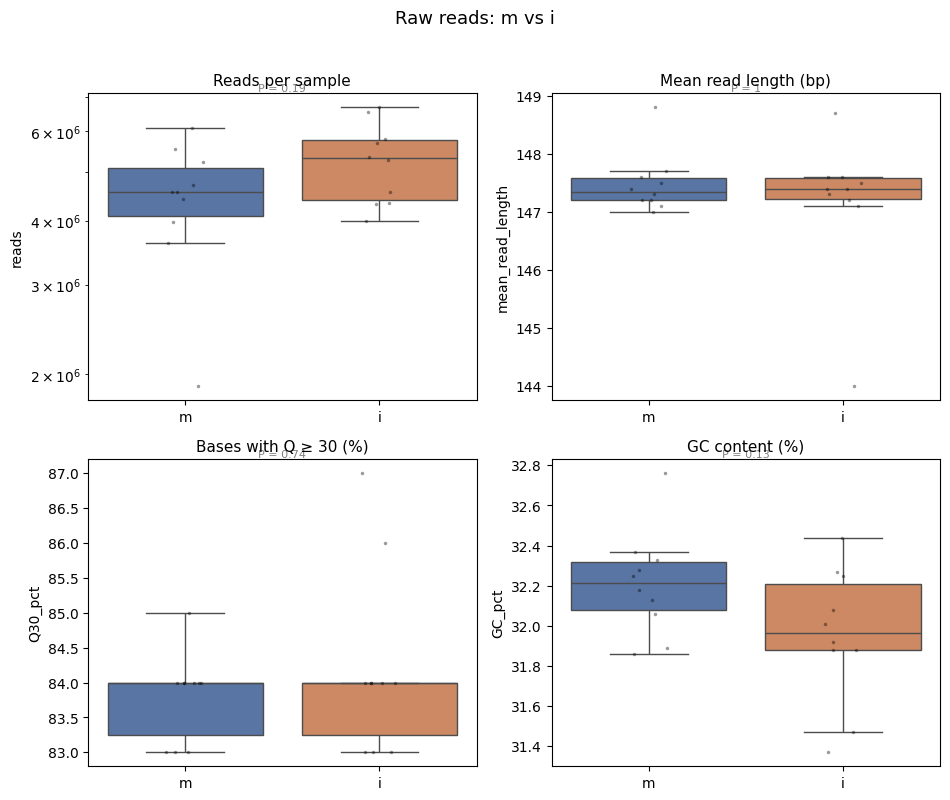

,metric,median_m,median_i,mannwhitney_P
0,Reads per sample,4560874.000,5311598.000,0.185877
1,Mean read length (bp),147.350,147.400,1.000000
2,Bases with Q ≥ 30 (%),84.000,84.000,0.736624
3,GC content (%),32.215,31.965,0.130281


In [11]:
metrics = {"reads": "Reads per sample", "mean_read_length": "Mean read length (bp)"}
for c, lab in [("Q30_pct", "Bases with Q ≥ 30 (%)"), ("GC_pct", "GC content (%)")]:
    if c in raw.columns:
        metrics[c] = lab
stats_raw = compare_morphs(raw, metrics, ncols=2, logy=("reads",), title="Raw reads: m vs i")
display(stats_raw)

Very good news is that we do not seem to see a significant difference between the morphs in terms of technical quality.

## 6. Quality Control on the Raw Reads with FastQC and MultiQC

**FastQC** inspects the reads of one file and produces an HTML report with about a dozen modules. **MultiQC** then scans a folder of FastQC reports and merges them into one interactive page, so that hundreds of samples can be inspected at once. In the MultiQC page, each sample is a line or a dot, and bad samples stand out.

### 6.1 What to look for (and what to expect for this dataset)

| FastQC module | Good | Notes for this dataset |
|---|---|---|
| **Per base sequence quality** | median ≥ Q28 across the read; slight drop at the 3′ end is normal | strong drops indicate a sequencing problem |
| **Per sequence quality scores** | one sharp peak at high quality | a second, low-quality peak = bad reads |
| **Per base sequence content** | A/C/G/T lines roughly flat | the **first ~10 bases are often biased**. Haplotagging libraries are made with the **Tn5 transposase**, which has an insertion-sequence preference, so FastQC will often "warn" or "fail" this module. This is **expected and not a problem** |
| **Per sequence GC content** | one peak, near the genome's GC | Lepidoptera genomes are AT-rich (GC roughly 30-40 %). Extra peaks suggest **contamination** (bacteria, parasites, *Wolbachia*) |
| **Sequence length distribution** | one value, or narrow | varied lengths mean the reads were already trimmed |
| **Sequence duplication levels** | low | at **low coverage** a high rate points to PCR duplicates or very low library complexity |
| **Overrepresented sequences / Adapter content** | none | adapters appear when the DNA fragment is shorter than the read |

> **Interpret with care:** FastQC's PASS/WARN/FAIL flags were designed for typical whole-genome data. Judge each flag in the context of the library type.

### 6.2 Run FastQC

We run FastQC on all samples, using all available CPU cores in parallel (one thread per FastQC process). Samples that already have a report are skipped, so this cell can be safely re-run.

In [12]:
%%bash
set -euo pipefail
n=$(ls "$LINK_DIR"/*.fastq.gz | wc -l)
echo "FastQC on raw reads: $n files, $THREADS parallel jobs"
for fq in "$LINK_DIR"/*.fastq.gz; do
    s=$(basename "$fq" .fastq.gz)
    [ -s "$QC_RAW/${s}_fastqc.html" ] || echo "$fq"
done | xargs -r -P "$THREADS" -I{} fastqc --quiet --threads 1 --outdir "$QC_RAW" {}
echo "Reports available: $(ls "$QC_RAW"/*_fastqc.html | wc -l)"

FastQC on raw reads: 20 files, 2 parallel jobs
Reports available: 455


### 6.3 Aggregate the reports with MultiQC

MultiQC finds all `*_fastqc.zip` files in the folder and writes `multiqc_before_adapter_removal.html` together with a `multiqc_data/` folder holding the underlying tables.

In [13]:
%%bash
multiqc "$QC_RAW" -o "$QC_RAW" -n multiqc_before_adapter_removal --force --quiet
ls -lh "$QC_RAW"/multiqc_before_adapter_removal.html

-rw------- 1 root root 8.8M Nov  8 19:39 /content/drive/MyDrive/GWAS/QC_before_adapter_removal/multiqc_before_adapter_removal.html


### 6.4 Open the MultiQC report

The HTML file is saved on Google Drive in `QC_before_adapter_removal/`. Download it to your computer (set `DOWNLOAD_REPORTS = True` in Section 3.1 and run the cell below, or download the file from Drive manually) and look at, in this order: **General Statistics**, **Sequence Quality Histograms**, **Per Base Sequence Content**, **Adapter Content**, and **Sequence Duplication Levels**.

In MultiQC you can colour samples by a *highlight* pattern (for example sample IDs of the `i` morph) to see if one group behaves differently.

In [14]:
# Optional: set DOWNLOAD_REPORTS = True in Section 3.1 to download the report to your computer
if DOWNLOAD_REPORTS:
    from google.colab import files
    files.download(str(DIRS["qc_raw"] / "multiqc_before_adapter_removal.html"))
else:
    print("Report is on Drive:", DIRS["qc_raw"] / "multiqc_before_adapter_removal.html")

Report is on Drive: /content/drive/MyDrive/GWAS/QC_before_adapter_removal/multiqc_before_adapter_removal.html


## 7. Adapter and Quality Trimming with fastp

### 7.1 Why trim?

During library preparation, **adapter sequences** are attached to both ends of each DNA fragment. If a fragment is shorter than the read length, the sequencer reads through the fragment and into the adapter. Adapter sequence does not exist in the genome, so such reads align poorly (or not at all) unless the adapter is removed. Likewise, the last bases of a read often have lower quality and produce **mismatches**, which can look like genetic variants.

> **A note about this dataset.** According to the paper, the authors cut adapters and low-quality ends with Trimmomatic *before* mapping, and the ENA archive holds BAM files (see `ENA_runs_full.tsv`). Your small FASTQ files were therefore most likely derived from reads that were already trimmed, so we **expect very little adapter content**. Trimming here is still a good habit and a nice way to *verify* that expectation: a low "adapter trimmed" fraction in the fastp report is the result we hope for.

### 7.2 fastp parameters

**fastp** detects adapters automatically (no adapter sequence needed for single-end data), trims them, filters low-quality reads, and writes a JSON report that we can parse in Python.

| Option | Meaning | Value used |
|---|---|---|
| `-i` / `-o` | input / output FASTQ (gzipped) | |
| `--qualified_quality_phred` (`-q`) | a base is "qualified" if its Phred score ≥ this | `MIN_QUAL` = 20 |
| `--unqualified_percent_limit` (`-u`) | discard a read if **more than this percentage** of its bases are unqualified | `MAX_UNQUAL_PCT` = 30 |
| `--length_required` (`-l`) | discard reads shorter than this after trimming | `MIN_LEN` = 50 |
| `--cut_tail` | slide a 4-base window from the 3′ end and cut while its mean quality is below the threshold | on |
| `--cut_tail_mean_quality` | the quality threshold for `--cut_tail` | `MIN_QUAL` |
| `-j` / `-h` | JSON / HTML report | per sample |
| `-R` | report title | the sample ID |

Each sample is processed once; finished samples are skipped when you re-run the cell.

In [15]:
%%bash
set -euo pipefail
mkdir -p "$TRIMMED/fastp_reports"
for sample in $(tail -n +2 "$SAMPLE_SHEET" | cut -f1); do
    out="$TRIMMED/${sample}.fastq.gz"
    if [ -s "$out" ] && [ -s "$TRIMMED/fastp_reports/${sample}.json" ]; then
        continue
    fi
    echo "Trimming $sample ..."
    fastp \
        -i "$LINK_DIR/${sample}.fastq.gz" \
        -o "$out.tmp.gz" \
        --qualified_quality_phred "$MIN_QUAL" \
        --unqualified_percent_limit "$MAX_UNQUAL_PCT" \
        --length_required "$MIN_LEN" \
        --cut_tail --cut_tail_mean_quality "$MIN_QUAL" \
        --thread 2 \
        -R "$sample" \
        -j "$TRIMMED/fastp_reports/${sample}.json" \
        -h "$TRIMMED/fastp_reports/${sample}.html" \
        2> "$LOGS/fastp_${sample}.log"
    mv "$out.tmp.gz" "$out"
done
echo "Trimmed files: $(ls "$TRIMMED"/*.fastq.gz | wc -l)"

Trimmed files: 455


### 7.3 What did fastp remove?

fastp's JSON report contains the number of reads before and after filtering, the reasons why reads were discarded (low quality, too short, too many N bases), and how many reads had adapters trimmed. We collect these numbers for all samples into one table.

In [16]:
rows = []
for js in sorted((DIRS["trimmed"] / "fastp_reports").glob("*.json")):
    d = json.load(open(js))
    b, a = d["summary"]["before_filtering"], d["summary"]["after_filtering"]
    f = d["filtering_result"]
    ad = d.get("adapter_cutting", {})
    rows.append(dict(
        sampleID=js.stem,
        reads_before=b["total_reads"], reads_after=a["total_reads"],
        low_quality=f.get("low_quality_reads", 0), too_short=f.get("too_short_reads", 0),
        too_many_N=f.get("too_many_N_reads", 0),
        adapter_trimmed_reads=ad.get("adapter_trimmed_reads", 0),
        mean_len_before=b["read1_mean_length"], mean_len_after=a["read1_mean_length"],
        q30_before=100 * b["q30_rate"], q30_after=100 * a["q30_rate"],
        gc_after=100 * a["gc_content"],
    ))
fp = pd.DataFrame(rows).merge(sheet[["sampleID", "morph"]], on="sampleID")
fp["pct_reads_kept"] = 100 * fp.reads_after / fp.reads_before
fp["pct_adapter_trimmed"] = 100 * fp.adapter_trimmed_reads / fp.reads_before
fp["pct_too_short"] = 100 * fp.too_short / fp.reads_before
fp["pct_low_quality"] = 100 * fp.low_quality / fp.reads_before
fp.to_csv(DIRS["trimmed"] / "fastp_summary.tsv", sep="\t", index=False)

print(f"Total reads before: {fp.reads_before.sum():,}   after: {fp.reads_after.sum():,}   "
      f"({100 * fp.reads_after.sum() / fp.reads_before.sum():.2f} % kept)")
display(fp[["pct_reads_kept", "pct_adapter_trimmed", "pct_too_short", "pct_low_quality",
            "mean_len_before", "mean_len_after", "q30_before", "q30_after"]].describe().T)

Total reads before: 97,218,636   after: 90,132,279   (92.71 % kept)


,count,mean,std,min,25%,50%,75%,max
pct_reads_kept,20.0,92.716154,0.674229,92.115011,92.351390,92.560932,92.892215,95.195391
pct_adapter_trimmed,20.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pct_too_short,20.0,0.047246,0.017597,0.032633,0.039090,0.042709,0.046087,0.113733
pct_low_quality,20.0,7.201601,0.688610,4.649952,7.028454,7.357801,7.574195,7.812024
mean_len_before,20.0,146.850000,0.988087,143.000000,147.000000,147.000000,147.000000,148.000000
mean_len_after,20.0,146.050000,0.944513,143.000000,146.000000,146.000000,146.000000,148.000000
q30_before,20.0,84.006845,1.046276,83.064200,83.358850,83.699650,84.042225,87.143300
q30_after,20.0,88.834940,0.723264,88.184600,88.498150,88.580650,88.677850,90.652400


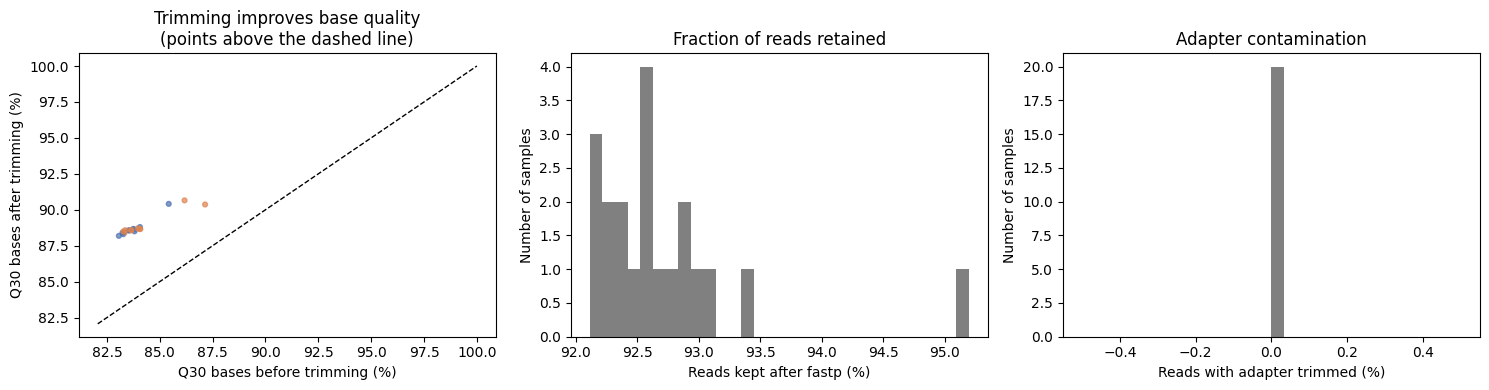

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(fp.q30_before, fp.q30_after, c=fp.morph.map(MORPH_COLORS), s=12, alpha=0.7)
lims = [min(fp.q30_before.min(), fp.q30_after.min()) - 1, 100]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set(xlabel="Q30 bases before trimming (%)", ylabel="Q30 bases after trimming (%)",
            title="Trimming improves base quality\n(points above the dashed line)")

axes[1].hist(fp.pct_reads_kept, bins=30, color="grey")
axes[1].set(xlabel="Reads kept after fastp (%)", ylabel="Number of samples", title="Fraction of reads retained")

axes[2].hist(fp.pct_adapter_trimmed, bins=30, color="grey")
axes[2].set(xlabel="Reads with adapter trimmed (%)", ylabel="Number of samples", title="Adapter contamination")
plt.tight_layout(); plt.show()

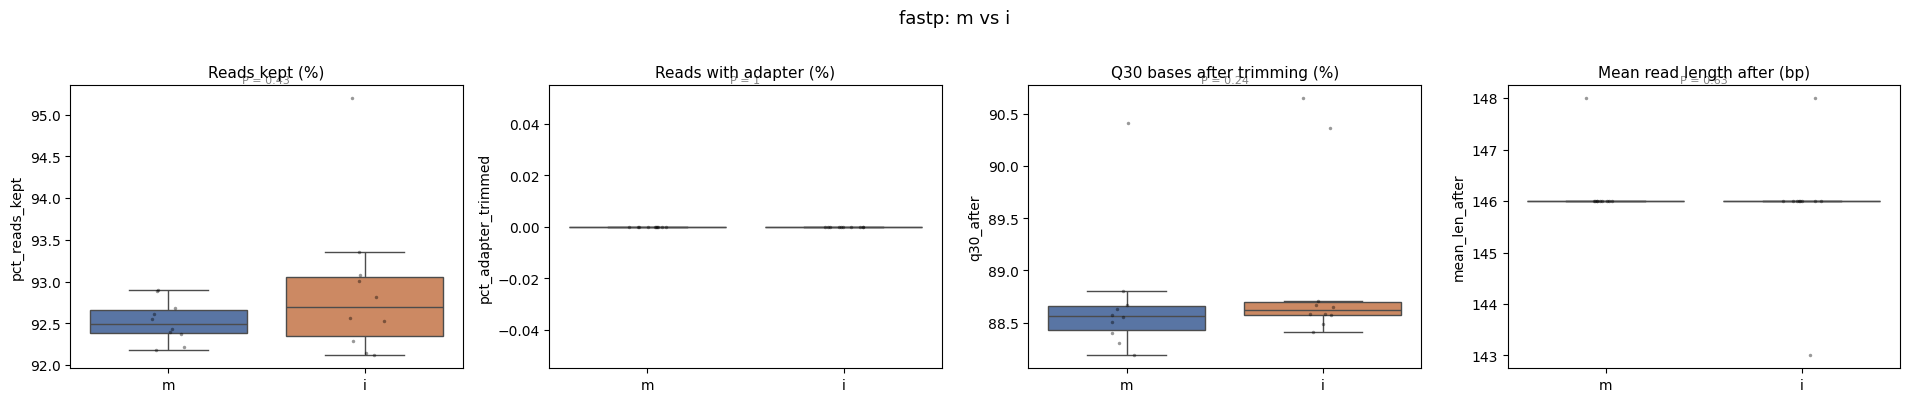

,metric,median_m,median_i,mannwhitney_P
0,Reads kept (%),92.494447,92.690839,0.427355
1,Reads with adapter (%),0.000000,0.000000,1.000000
2,Q30 bases after trimming (%),88.564200,88.617700,0.241322
3,Mean read length after (bp),146.000000,146.000000,0.626354


In [18]:
metrics = {"pct_reads_kept": "Reads kept (%)", "pct_adapter_trimmed": "Reads with adapter (%)",
           "q30_after": "Q30 bases after trimming (%)", "mean_len_after": "Mean read length after (bp)"}
stats_fp = compare_morphs(fp, metrics, ncols=4, title="fastp: m vs i")
display(stats_fp)

## 8. Quality Control on the Trimmed Reads

We repeat FastQC on the trimmed reads and run MultiQC again, this time **including the per-sample fastp JSON reports** in the same MultiQC page (MultiQC understands fastp). Compare the "after" report with the "before" report:

* Are the per-base quality curves higher at the 3′ end?
* Has the adapter-content curve flattened to zero?
* Has the read-length distribution become narrower, or shifted?

In [19]:
%%bash
set -euo pipefail
echo "FastQC on trimmed reads: $(ls "$TRIMMED"/*.fastq.gz | wc -l) files"
for fq in "$TRIMMED"/*.fastq.gz; do
    s=$(basename "$fq" .fastq.gz)
    [ -s "$QC_TRIM/${s}_fastqc.html" ] || echo "$fq"
done | xargs -r -P "$THREADS" -I{} fastqc --quiet --threads 1 --outdir "$QC_TRIM" {}

multiqc "$QC_TRIM" "$TRIMMED/fastp_reports" -o "$QC_TRIM" -n multiqc_after_adapter_removal --force --quiet
ls -lh "$QC_TRIM"/multiqc_after_adapter_removal.html

FastQC on trimmed reads: 455 files
-rw------- 1 root root 12M Nov  8 19:42 /content/drive/MyDrive/GWAS/QC_after_adapter_removal/multiqc_after_adapter_removal.html


In [20]:
if DOWNLOAD_REPORTS:
    from google.colab import files
    files.download(str(DIRS["qc_trim"] / "multiqc_after_adapter_removal.html"))
else:
    print("Report is on Drive:", DIRS["qc_trim"] / "multiqc_after_adapter_removal.html")

Report is on Drive: /content/drive/MyDrive/GWAS/QC_after_adapter_removal/multiqc_after_adapter_removal.html


## 9. Download and Index the *H. misippus* Reference Genome

### 9.1 Which reference?

Reads are aligned to a **reference genome**. We use the *H. misippus* assembly **HypMis_v2** published by Orteu et al. (2024, *Genome Biology and Evolution* 16: evae215), which is also the reference used in the GWAS paper. Facts from the assembly paper:

* Built from **one family by trio binning**: PacBio HiFi reads of an offspring were assembled with hifiasm into two parental haplotypes, and the Hi-C data of another individual were used to scaffold them into chromosomes. **HypMis_v2 is the Hi-C-scaffolded maternal haplotype (haplotype 2)** and includes both the **Z** and **W** sex chromosomes.
* About **438 Mb** in 218 scaffolds: **32 chromosome-level scaffolds** (30 autosomes + Z + W) and 186 small unplaced scaffolds. Scaffold N50 ≈ 14.6 Mb. BUSCO completeness ≈ 98.7 %.
* The reference is a **haploid** representation of a diploid individual. For the M locus, that individual was an **M homozygote**, so the reference carries the TE insertions.
* Public records: NCBI BioProject **PRJNA1086912** (primary assembly) and the Sanger Tree of Life portal `tolqc.cog.sanger.ac.uk/durbin/jiggins/Hypolimnas_misippus/`.

### 9.2 Find the assembly at NCBI on the fly

Rather than hard-coding a file name, the cell below asks **NCBI's E-utilities** web service for the assembly belonging to BioProject PRJNA1086912 and derives the download address of the genomic FASTA from the answer. It then **prints every candidate it found**, so you can check that the right assembly was selected.

If NCBI is unreachable, or you want a different assembly, set `ASSEMBLY_ACCESSION` (for example `"GCA_xxxxxxxxx.1"`) or `REF_URL_OVERRIDE` (a direct link to a `.fa`/`.fna.gz` file, e.g. from the Sanger portal) in the cell.

In [21]:
BIOPROJECT = "PRJNA1086912"
ASSEMBLY_ACCESSION = None      # e.g. "GCA_000000000.1" to force a specific assembly
REF_URL_OVERRIDE = None        # e.g. a direct link to a .fa.gz file

EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"

def eutils(endpoint, **params):
    params.update(tool="colab_gwas_course", retmode="json")
    url = EUTILS + endpoint + "?" + urllib.parse.urlencode(params)
    with urllib.request.urlopen(url, timeout=60) as r:
        return json.load(r)

def find_assemblies(term):
    ids = eutils("esearch.fcgi", db="assembly", term=term, retmax=20)["esearchresult"]["idlist"]
    if not ids:
        return pd.DataFrame()
    summ = eutils("esummary.fcgi", db="assembly", id=",".join(ids))["result"]
    rows = []
    for uid in ids:
        d = summ[uid]
        rows.append(dict(accession=d.get("assemblyaccession"), name=d.get("assemblyname"),
                         organism=d.get("organism"), status=d.get("assemblystatus"),
                         contig_n50=d.get("contign50"), scaffold_n50=d.get("scaffoldn50"),
                         last_updated=d.get("lastupdatedate"), ftp=d.get("ftppath_genbank")))
    return pd.DataFrame(rows)

if REF_URL_OVERRIDE:
    REF_URL = REF_URL_OVERRIDE
    REF_BASE_URL = ""
    print("Using the manually supplied reference URL:", REF_URL)
else:
    cands = find_assemblies(f"{BIOPROJECT}[BioProject]")
    if cands.empty:
        print(f"No assembly record directly linked to {BIOPROJECT}; searching by organism instead ...")
        cands = find_assemblies('"Hypolimnas misippus"[Organism]')
    if ASSEMBLY_ACCESSION:
        cands = find_assemblies(f"{ASSEMBLY_ACCESSION}[Assembly Accession]")
    assert not cands.empty, "No assembly found. Set ASSEMBLY_ACCESSION or REF_URL_OVERRIDE."
    print("Candidate assemblies found at NCBI:")
    display(cands.drop(columns="ftp"))
    row = cands.iloc[0]
    print(f"--> using {row.accession} ({row['name']})")
    assert row.ftp, "This record has no GenBank FTP path. Set REF_URL_OVERRIDE."
    REF_BASE_URL = row.ftp.replace("ftp://", "https://")
    REF_URL = f"{REF_BASE_URL}/{REF_BASE_URL.rsplit('/', 1)[-1]}_genomic.fna.gz"

REF_NAME = "HypMis_v2"
REF_FASTA = DIRS["ref"] / f"{REF_NAME}.fa"
os.environ.update(REF_URL=REF_URL, REF_BASE_URL=REF_BASE_URL, REF_NAME=REF_NAME, REF_FASTA=str(REF_FASTA))
print("Download URL:", REF_URL)

Candidate assemblies found at NCBI:


,accession,name,organism,status,contig_n50,scaffold_n50,last_updated
0,GCA_037950945.1,ASM3795094v1,Hypolimnas misippus (butterflies),Scaffold,13018674,14598500,2024/04/03 00:00


--> using GCA_037950945.1 (ASM3795094v1)
Download URL: https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/037/950/945/GCA_037950945.1_ASM3795094v1/GCA_037950945.1_ASM3795094v1_genomic.fna.gz


### 9.3 Download, verify and decompress

The download is placed in `reference_HypMis_v2/` on Drive. After downloading, we compare the file's **MD5 checksum** with the value published by NCBI. A checksum is a short fingerprint of a file's content: if even one byte changed during the download, the fingerprints differ. Steps are skipped when the files already exist.

In [22]:
%%bash
set -euo pipefail
mkdir -p "$REF_DIR"
GZ="$REF_DIR/${REF_NAME}.fa.gz"

if [ ! -s "$REF_FASTA" ]; then
    if [ ! -s "$GZ" ]; then
        echo "Downloading $REF_URL"
        wget -q -O "$GZ.tmp" "$REF_URL"
        mv "$GZ.tmp" "$GZ"
    fi
    if [ -n "${REF_BASE_URL:-}" ]; then
        fname=$(basename "$REF_URL")
        expected=$(curl -fsSL "$REF_BASE_URL/md5checksums.txt" | grep -F "$fname" | awk '{print $1}' || true)
        actual=$(md5sum "$GZ" | awk '{print $1}')
        if [ -z "$expected" ]; then
            echo "WARNING: could not fetch the NCBI checksum; skipping verification"
        elif [ "$expected" = "$actual" ]; then
            echo "MD5 checksum OK ($actual)"
        else
            echo "ERROR: checksum mismatch (expected $expected, got $actual)"; rm -f "$GZ"; exit 1
        fi
    fi
    gunzip -c "$GZ" > "$REF_FASTA.tmp"
    mv "$REF_FASTA.tmp" "$REF_FASTA"
fi
ls -lh "$REF_DIR"
echo
echo "Number of sequences: $(grep -c '>' "$REF_FASTA")"
grep '>' "$REF_FASTA" | head -n 5 || true

total 1.3G
-rw------- 1 root root  26K Nov  8 11:25 HypMis_v2.dict
-rw------- 1 root root 424M Nov  8 11:09 HypMis_v2.fa
-rw------- 1 root root 1.8K Nov  8 11:25 HypMis_v2.fa.amb
-rw------- 1 root root  27K Nov  8 11:25 HypMis_v2.fa.ann
-rw------- 1 root root 418M Nov  8 11:25 HypMis_v2.fa.bwt
-rw------- 1 root root 8.5K Nov  8 11:25 HypMis_v2.fa.fai
-rw------- 1 root root 135M Nov  8 11:09 HypMis_v2.fa.gz
-rw------- 1 root root 105M Nov  8 11:25 HypMis_v2.fa.pac
-rw------- 1 root root 209M Nov  8 11:25 HypMis_v2.fa.sa

Number of sequences: 218
>JBBEEQ010000001.1 Hypolimnas misippus isolate Offspring 1 HiC_scaffold_1, whole genome shotgun sequence
>JBBEEQ010000010.1 Hypolimnas misippus isolate Offspring 1 HiC_scaffold_10, whole genome shotgun sequence
>JBBEEQ010000100.1 Hypolimnas misippus isolate Offspring 1 HiC_scaffold_100, whole genome shotgun sequence
>JBBEEQ010000101.1 Hypolimnas misippus isolate Offspring 1 HiC_scaffold_101, whole genome shotgun sequence
>JBBEEQ010000102.1 Hypol

### 9.4 Index the reference

Two kinds of index are needed:

* **BWA index** (`bwa index`): builds a compressed suffix-array / Burrows-Wheeler (FM) index of the genome so that BWA can find where a read matches without scanning the whole genome. It produces five files: `.amb`, `.ann`, `.bwt`, `.pac`, `.sa`.
* **FASTA index** (`samtools faidx` → `.fai`) and a **sequence dictionary** (`samtools dict` → `.dict`): lists of sequence names, lengths and file offsets, needed by SAMtools and many downstream tools (for example GATK).

Indexing a 440 Mb genome takes roughly **10-20 minutes** and a few GB of memory. For speed we build the index on Colab's **local disk** and then copy the finished files to Drive. In later sessions the index is already on Drive and this step is skipped.

In [23]:
%%bash
set -euo pipefail
if [ -s "${REF_FASTA}.bwt" ] && [ -s "${REF_FASTA}.fai" ] && [ -s "$REF_DIR/${REF_NAME}.dict" ]; then
    echo "Index already present on Drive: skipping."
else
    mkdir -p "$SCRATCH/ref"
    cp "$REF_FASTA" "$SCRATCH/ref/${REF_NAME}.fa"
    cd "$SCRATCH/ref"
    echo "[$(date +%T)] bwa index ..."
    bwa index "${REF_NAME}.fa" 2> "$LOGS/bwa_index.log"
    echo "[$(date +%T)] samtools faidx / dict ..."
    samtools faidx "${REF_NAME}.fa"
    samtools dict "${REF_NAME}.fa" -o "${REF_NAME}.dict"
    cp "${REF_NAME}".fa.amb "${REF_NAME}".fa.ann "${REF_NAME}".fa.bwt "${REF_NAME}".fa.pac \
       "${REF_NAME}".fa.sa "${REF_NAME}".fa.fai "${REF_NAME}".dict "$REF_DIR/"
    echo "[$(date +%T)] done"
fi
ls -lh "$REF_DIR"

Index already present on Drive: skipping.
total 1.3G
-rw------- 1 root root  26K Nov  8 11:25 HypMis_v2.dict
-rw------- 1 root root 424M Nov  8 11:09 HypMis_v2.fa
-rw------- 1 root root 1.8K Nov  8 11:25 HypMis_v2.fa.amb
-rw------- 1 root root  27K Nov  8 11:25 HypMis_v2.fa.ann
-rw------- 1 root root 418M Nov  8 11:25 HypMis_v2.fa.bwt
-rw------- 1 root root 8.5K Nov  8 11:25 HypMis_v2.fa.fai
-rw------- 1 root root 135M Nov  8 11:09 HypMis_v2.fa.gz
-rw------- 1 root root 105M Nov  8 11:25 HypMis_v2.fa.pac
-rw------- 1 root root 209M Nov  8 11:25 HypMis_v2.fa.sa


### 9.5 Inspect the reference: how does it compare with the paper?

We read the FASTA index and the FASTA headers and build a **chromosome table**. We then compute the same statistics as in the assembly paper (number of sequences, total length, N50) to confirm that this is the assembly we think it is.

**N50** is a measure of contiguity: if you sort the sequences from the longest to the shortest and add up their lengths, N50 is the length of the sequence at which the running total reaches half of the genome. A larger N50 means a more contiguous assembly.

In [24]:
fai = pd.read_csv(str(REF_FASTA) + ".fai", sep="\t", header=None,
                  names=["contig", "length", "offset", "linebases", "linewidth"])
hdr = subprocess.run(["grep", ">", str(REF_FASTA)], capture_output=True, text=True).stdout.splitlines()
desc = {h[1:].split(" ", 1)[0]: (h[1:].split(" ", 1) + [""])[1] for h in hdr}
fai["description"] = fai.contig.map(desc)
fai["label"] = fai.description.str.extract(r"(?:chromosome|scaffold)[:\s_]+([A-Za-z0-9]+)", expand=False)
GENOME_SIZE = int(fai.length.sum())

def n50(lengths):
    l = np.sort(np.asarray(lengths))[::-1]
    return int(l[np.cumsum(l) >= l.sum() / 2][0])

print(f"Sequences      : {len(fai)}                      (paper: 218)")
print(f"Total length   : {GENOME_SIZE/1e6:,.2f} Mb              (paper: 438.07 Mb)")
print(f"N50            : {n50(fai.length)/1e6:,.2f} Mb              (paper: 14.6 Mb)")
print(f"Sequences > 6 Mb (chromosome-level): {(fai.length > 6e6).sum()}   (paper: 32 = 30 autosomes + Z + W)")
os.environ["GENOME_SIZE"] = str(GENOME_SIZE)

print("\nLargest sequences:")
display(fai.sort_values("length", ascending=False).head(34)[["contig", "length", "label", "description"]]
        .reset_index(drop=True))

Sequences      : 218                      (paper: 218)
Total length   : 438.07 Mb              (paper: 438.07 Mb)
N50            : 14.60 Mb              (paper: 14.6 Mb)
Sequences > 6 Mb (chromosome-level): 32   (paper: 32 = 30 autosomes + Z + W)

Largest sequences:


,contig,length,label,description
0,JBBEEQ010000001.1,22152366,1,Hypolimnas misippus isolate Offspring 1 HiC_sc...
1,JBBEEQ010000017.1,17698500,17,Hypolimnas misippus isolate Offspring 1 HiC_sc...
2,JBBEEQ010000032.1,16801067,32,Hypolimnas misippus isolate Offspring 1 HiC_sc...
3,JBBEEQ010000018.1,16564601,18,Hypolimnas misippus isolate Offspring 1 HiC_sc...
4,JBBEEQ010000010.1,16455000,10,Hypolimnas misippus isolate Offspring 1 HiC_sc...
5,JBBEEQ010000012.1,16414404,12,Hypolimnas misippus isolate Offspring 1 HiC_sc...
6,JBBEEQ010000029.1,15924875,29,Hypolimnas misippus isolate Offspring 1 HiC_sc...
7,JBBEEQ010000024.1,15818933,24,Hypolimnas misippus isolate Offspring 1 HiC_sc...
8,JBBEEQ010000023.1,15716625,23,Hypolimnas misippus isolate Offspring 1 HiC_sc...
9,JBBEEQ010000027.1,15323875,27,Hypolimnas misippus isolate Offspring 1 HiC_sc...


### 9.6 Identify chromosome 26 (the M locus) and the Z chromosome

The paper's coordinates refer to **"chromosome 26"** and the **Z chromosome** of HypMis_v2. In the NCBI version the sequences have accession-style names, so we use the label found in the FASTA header description to find them. **Please check the printout:** if the labels in your table above are named differently (for example `HiC_scaffold_26`), set `M_CHROM` or `Z_CHROM` by hand.

In [25]:
def contig_by_label(label):
    hit = fai.loc[fai.label == str(label), "contig"]
    return hit.iloc[0] if len(hit) else None

M_CHROM = contig_by_label("26")      # set manually if this is None or wrong, e.g. M_CHROM = "OZ123456.1"
Z_CHROM = contig_by_label("Z")       # the paper calls the Z chromosome "chromosome 1" in some figures

print("Chromosome 26 (M locus)   ->", M_CHROM, "" if M_CHROM else "NOT FOUND: set M_CHROM manually")
print("Z chromosome              ->", Z_CHROM, "" if Z_CHROM else "NOT FOUND: set Z_CHROM manually (optional)")
if M_CHROM:
    print(f"Length of chromosome 26: {int(fai.set_index('contig').loc[M_CHROM, 'length']):,} bp "
          "(the M locus lies at 6,731,000 - 6,743,400 bp)")

Chromosome 26 (M locus)   -> JBBEEQ010000026.1 
Z chromosome              -> None NOT FOUND: set Z_CHROM manually (optional)
Length of chromosome 26: 11,431,643 bp (the M locus lies at 6,731,000 - 6,743,400 bp)


## 10. Align the Trimmed Reads with BWA-MEM

### 10.1 How does `bwa mem` work?

For each read, BWA-MEM (Li 2013):

1. finds **seeds**: maximal exact matches between the read and the reference, using the FM-index we just built;
2. **chains** and ranks the seeds, then **extends** the best chains with a gapped (Smith-Waterman) alignment to produce a full alignment with mismatches, insertions and deletions;
3. reports a **mapping quality (MAPQ)**: a Phred-scaled estimate of the probability that the read was placed in the *wrong* location. MAPQ 60 means "unique and confident"; **MAPQ 0 means the read maps equally well to several places** (typically in repeats).

BWA-MEM2, used in the paper, is a faster re-implementation that gives essentially identical results; we use classic BWA-MEM here because it is lightweight in Colab.

### 10.2 Options we use

| Option | Meaning |
|---|---|
| `-t` | number of threads |
| `-R '@RG\tID:..\tSM:..'` | **Read group**: labels every read with its sample (`SM`), library (`LB`) and platform (`PL`). Downstream tools (ANGSD, GATK, bcftools) use `SM` to know which individual a read belongs to. **The sample name must be the CAM ID**, so that BAM files can be matched to the morph annotation. |
| pipe into `samtools sort` | sends the alignments straight into SAMtools, which sorts them by genomic coordinate and writes a compressed **BAM**, so no huge SAM file is ever written |
| `samtools index` | creates a `.bai` index, which allows fast access to any genomic region |

> **Low coverage and multi-mapping.** We keep all reads here, including MAPQ 0 reads. Filtering (for example MAPQ ≥ 10 or ≥ 20, as the paper's Wrath step did) belongs to the downstream analysis, where the choice can be tested.

The loop writes each BAM to a temporary name and renames it when finished, so an interrupted run never leaves a half-written file behind. Finished samples are skipped on re-run.

In [26]:
%%bash
set -euo pipefail
mkdir -p "$BAMS" "$SCRATCH/sort"
n_total=$(tail -n +2 "$SAMPLE_SHEET" | wc -l); i=0
for sample in $(tail -n +2 "$SAMPLE_SHEET" | cut -f1); do
    i=$((i+1))
    bam="$BAMS/${sample}.sorted.bam"
    if [ -s "${bam}.bai" ]; then continue; fi
    echo "[$i/$n_total] Aligning $sample ..."
    bwa mem -t "$THREADS" \
        -R "@RG\tID:${sample}\tSM:${sample}\tLB:${sample}\tPL:ILLUMINA\tPU:${sample}" \
        "$REF_FASTA" "$TRIMMED/${sample}.fastq.gz" 2> "$LOGS/bwa_${sample}.log" \
      | samtools sort -@ "$THREADS" -m 1G -T "$SCRATCH/sort/${sample}" -O bam -o "${bam}.tmp" -
    mv "${bam}.tmp" "$bam"
    samtools index "$bam"
done
echo "BAM files: $(ls "$BAMS"/*.sorted.bam | wc -l)"

[11/20] Aligning CAM035155 ...
[12/20] Aligning CAM035157 ...
[13/20] Aligning CAM035166 ...
[14/20] Aligning CAM035181 ...
[15/20] Aligning CAM035202 ...
[16/20] Aligning CAM035203 ...
[17/20] Aligning CAM035206 ...
[18/20] Aligning CAM035212 ...
[19/20] Aligning CAM035225 ...
[20/20] Aligning CAM035253 ...
BAM files: 455


[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 1 files and 2 in-memory blocks...
[bam_sort_core] merging from 1 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 1 files and 2 in-memory blocks...
[bam_sort_core] merging from 1 files and 2 in-memory blocks...


### 10.3 Look inside a BAM file

BAM is the compressed binary form of **SAM** (Sequence Alignment/Map), a tab-separated text format. A SAM file has a **header** (lines starting with `@`: reference sequences `@SQ`, read groups `@RG`, programs `@PG`) followed by **one line per alignment** with 11 mandatory columns:

| # | Field | Meaning |
|---|---|---|
| 1 | QNAME | read name |
| 2 | FLAG | bitwise code: is the read mapped? reverse strand? duplicate? ... |
| 3 | RNAME | reference sequence (chromosome) |
| 4 | POS | leftmost mapping position (1-based) |
| 5 | MAPQ | mapping quality |
| 6 | CIGAR | alignment description, e.g. `100M` = 100 matches/mismatches; `45M2D55M` = a 2-base deletion |
| 7-9 | RNEXT, PNEXT, TLEN | mate information (`*`, `0`, `0` for single-end reads) |
| 10 | SEQ | the read sequence |
| 11 | QUAL | the base qualities |

Let us look at the header and the first alignments of one BAM.

In [27]:
%%bash
first=$(ls "$BAMS"/*.sorted.bam | head -n 1)
echo "BAM file: $first"
echo; echo "--- header: @HD, @RG, @PG and the first 3 @SQ lines ---"
samtools view -H "$first" | grep -E "^@(HD|RG|PG)"
samtools view -H "$first" | grep "^@SQ" | head -n 3
echo; echo "--- first 3 alignments (columns 1-9 only) ---"
samtools view "$first" | head -n 3 | cut -f1-9

BAM file: /content/drive/MyDrive/GWAS/bams/CAM035143.sorted.bam

--- header: @HD, @RG, @PG and the first 3 @SQ lines ---
@HD	VN:1.5	SO:coordinate
@RG	ID:CAM035143	SM:CAM035143	LB:CAM035143	PL:ILLUMINA	PU:CAM035143
@PG	ID:bwa	PN:bwa	VN:0.7.19-r1273	CL:bwa mem -t 2 -R @RG\tID:CAM035143\tSM:CAM035143\tLB:CAM035143\tPL:ILLUMINA\tPU:CAM035143 /content/drive/MyDrive/GWAS/reference_HypMis_v2/HypMis_v2.fa /content/drive/MyDrive/GWAS/trimmed_fastqs/CAM035143.fastq.gz
@PG	ID:samtools	PN:samtools	PP:bwa	VN:1.25	CL:samtools sort -@ 2 -m 1G -T /content/work/scratch/sort/CAM035143 -O bam -o /content/drive/MyDrive/GWAS/bams/CAM035143.sorted.bam.tmp -
@PG	ID:samtools.1	PN:samtools	PP:samtools	VN:1.25	CL:samtools view -H /content/drive/MyDrive/GWAS/bams/CAM035143.sorted.bam
@SQ	SN:JBBEEQ010000001.1	LN:22152366
@SQ	SN:JBBEEQ010000010.1	LN:16455000
@SQ	SN:JBBEEQ010000100.1	LN:2433

--- first 3 alignments (columns 1-9 only) ---
ST-J00101:184:HH5KFBBXY:8:1121:15838:5939	0	JBBEEQ010000001.1	459	60	150M	*	0	

In [28]:
# Decode one alignment, including its FLAG bits
first_bam = sorted(DIRS["bams"].glob("*.sorted.bam"))[0]
line = subprocess.run(f"samtools view -F 4 {first_bam} | head -n 1", shell=True,
                      capture_output=True, text=True).stdout.rstrip("\n").split("\t")
assert len(line) >= 11, "No mapped reads in the first BAM file?"
names = ["QNAME", "FLAG", "RNAME", "POS", "MAPQ", "CIGAR", "RNEXT", "PNEXT", "TLEN", "SEQ", "QUAL"]
display(pd.DataFrame({"field": names, "value": [v if len(v) < 60 else v[:57] + "..." for v in line[:11]]}))
print("optional tags:", line[11:])

FLAG_BITS = {1: "paired", 2: "proper pair", 4: "unmapped", 8: "mate unmapped", 16: "reverse strand",
             32: "mate reverse strand", 64: "first in pair", 128: "second in pair",
             256: "secondary alignment", 512: "fails QC", 1024: "PCR/optical duplicate",
             2048: "supplementary alignment"}
flag = int(line[1])
print(f"\nFLAG {flag} = {[txt for bit, txt in FLAG_BITS.items() if flag & bit] or ['forward strand, primary alignment']}")
print("NM = edit distance to the reference, AS = alignment score, XS = score of the best secondary hit (if XS >= AS the read is ambiguous), "
      "RG = read group")

,field,value
0,QNAME,ST-J00101:184:HH5KFBBXY:8:1121:15838:5939
1,FLAG,0
2,RNAME,JBBEEQ010000001.1
3,POS,459
4,MAPQ,60
5,CIGAR,150M
6,RNEXT,*
7,PNEXT,0
8,TLEN,0
9,SEQ,ACATGATGCTTTATAAAAATACATCAATATCTCATAATTTGACGTT...


optional tags: ['NM:i:2', 'MD:Z:8T106C34', 'AS:i:140', 'XS:i:22', 'RG:Z:CAM035143']

FLAG 0 = ['forward strand, primary alignment']
NM = edit distance to the reference, AS = alignment score, XS = score of the best secondary hit (if XS >= AS the read is ambiguous), RG = read group


## 11. Quality Control of the Alignments

Three SAMtools commands summarise a BAM file:

* **`samtools flagstat`**: counts of reads by FLAG category (total, mapped, duplicates, ...).
* **`samtools stats`**: a detailed report (read counts, bases mapped, error rate, MAPQ and read-length distributions, ...).
* **`samtools idxstats`**: reads mapped **per chromosome**, which we use for a sex-chromosome check.

We run all three for every sample and write the results to `QC_alignment/`. MultiQC will merge them into a single report.

In [29]:
%%bash
set -euo pipefail
mkdir -p "$QC_ALN"
for sample in $(tail -n +2 "$SAMPLE_SHEET" | cut -f1); do
    bam="$BAMS/${sample}.sorted.bam"
    [ -s "$QC_ALN/${sample}.idxstats" ] && continue
    samtools flagstat -@ "$THREADS" "$bam" > "$QC_ALN/${sample}.flagstat"
    samtools stats    -@ "$THREADS" "$bam" > "$QC_ALN/${sample}.stats"
    samtools idxstats "$bam"               > "$QC_ALN/${sample}.idxstats"
done
multiqc "$QC_ALN" -o "$QC_ALN" -n multiqc_alignment --force --quiet
echo "=== flagstat of the first sample ==="
cat "$QC_ALN/$(tail -n +2 "$SAMPLE_SHEET" | cut -f1 | head -n 1).flagstat"

=== flagstat of the first sample ===
3440124 + 0 in total (QC-passed reads + QC-failed reads)
3343685 + 0 primary
0 + 0 secondary
96439 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
3406708 + 0 mapped (99.03% : N/A)
3310269 + 0 primary mapped (99.00% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


### 11.1 Collect the statistics for all samples

From `samtools stats` we extract:

| Metric | Meaning | Why it matters for GWAS |
|---|---|---|
| `reads` | reads entering the aligner | sequencing effort |
| `pct_mapped` | % of reads aligned to the reference | low values = contamination, wrong reference, or poor DNA |
| `mean_depth` | `bases mapped (cigar)` ÷ genome size | **coverage** per individual, which determines how many genotypes can be called |
| `pct_MQ0` | % of mapped reads with MAPQ 0 | multi-mapping reads (repeats). *H. misippus* is ~42 % repeats |
| `error_rate` | mismatches per aligned base | high values = poor reads or divergent contamination |
| `mean_quality` | mean base quality | |

In [30]:
def parse_stats(path):
    d = {}
    for line in open(path):
        if line.startswith("SN\t"):
            parts = line.rstrip("\n").split("\t")
            try:
                d[parts[1].rstrip(":")] = float(parts[2].split()[0])
            except ValueError:
                pass
    return d

samples = list(sheet.sampleID)
aln = pd.DataFrame({s: parse_stats(DIRS["qc_aln"] / f"{s}.stats") for s in samples}).T
aln.index.name = "sampleID"
aln = aln.reset_index().merge(sheet[["sampleID", "morph"]], on="sampleID")
aln["reads"] = aln["raw total sequences"]
aln["pct_mapped"] = 100 * aln["reads mapped"] / aln["raw total sequences"]
aln["mean_depth"] = aln["bases mapped (cigar)"] / GENOME_SIZE
aln["pct_MQ0"] = 100 * aln["reads MQ0"] / aln["reads mapped"].replace(0, np.nan)
aln["error_rate"] = aln["error rate"]
aln["mean_quality"] = aln["average quality"]

# flag potential problem samples with robust z-scores (|z| > 3.5 is a common outlier rule)
aln["z_reads"] = robust_z(np.log10(aln.reads.clip(lower=1)))
aln["z_mapped"] = robust_z(aln.pct_mapped)
aln["flag_low_yield"] = aln.z_reads < -3.5
aln["flag_low_mapping"] = aln.z_mapped < -3.5

summary_cols = ["sampleID", "morph", "reads", "pct_mapped", "mean_depth", "pct_MQ0", "error_rate",
                "mean_quality", "flag_low_yield", "flag_low_mapping"]
aln[summary_cols].to_csv(PROJECT_DIR / "alignment_summary.tsv", sep="\t", index=False)

print(f"Samples: {len(aln)};  total reads: {int(aln.reads.sum()):,};  "
      f"overall mapping rate: {100 * aln['reads mapped'].sum() / aln['raw total sequences'].sum():.2f} %")
print(f"Mean depth per sample: median {aln.mean_depth.median():.4f}x, range {aln.mean_depth.min():.4f}x - {aln.mean_depth.max():.4f}x"
      "   (paper, full data: ~0.81x on average)")
display(aln[["reads", "pct_mapped", "mean_depth", "pct_MQ0", "error_rate", "mean_quality"]].describe().T)
flagged = aln[aln.flag_low_yield | aln.flag_low_mapping]
print(f"\nSamples flagged as potential outliers: {len(flagged)}")
if len(flagged):
    display(flagged[summary_cols])

Samples: 20;  total reads: 90,132,279;  overall mapping rate: 98.43 %
Mean depth per sample: median 1.3884x, range 0.5587x - 2.0418x   (paper, full data: ~0.81x on average)


,count,mean,std,min,25%,50%,75%,max
reads,20.0,4.506614e+06,1.023526e+06,1.750535e+06,4.025270e+06,4.300434e+06,5.181360e+06,6.247663e+06
pct_mapped,20.0,9.832267e+01,2.355818e+00,8.862172e+01,9.890695e+01,9.905681e+01,9.912238e+01,9.922146e+01
mean_depth,20.0,1.449320e+00,3.417944e-01,5.586582e-01,1.272865e+00,1.388406e+00,1.674239e+00,2.041828e+00
pct_MQ0,20.0,1.067707e+01,4.282662e-01,9.865345e+00,1.038786e+01,1.066096e+01,1.088002e+01,1.167468e+01
error_rate,20.0,2.804470e-02,3.203995e-04,2.716485e-02,2.784264e-02,2.813153e-02,2.824526e-02,2.847564e-02
mean_quality,20.0,3.722500e+01,2.268201e-01,3.700000e+01,3.710000e+01,3.715000e+01,3.720000e+01,3.780000e+01



Samples flagged as potential outliers: 4


,sampleID,morph,reads,pct_mapped,mean_depth,pct_MQ0,error_rate,mean_quality,flag_low_yield,flag_low_mapping
2,CAM035145,m,4109374.0,96.996404,1.302357,10.686123,0.028191,37.2,False,True
4,CAM035147,m,4218237.0,97.715467,1.347762,10.349113,0.028476,37.1,False,True
7,CAM035150,m,1750535.0,97.986558,0.558658,10.758129,0.028427,37.1,True,True
16,CAM035206,i,4034056.0,88.621725,1.169424,9.865345,0.027165,37.2,False,True


### 11.2 Do the morphs differ in alignment quality or depth?

This is the **key confounder check** before any association test. If the `i` and `m` groups differ **significantly** in depth, mapping rate or error rate, then genotype calling quality will differ between cases and controls, which can generate spurious associations. In that case consider using depth as a covariate or restricting to well-covered samples.

With 57 `i` versus 275 `m` samples, remember that a *non-significant* result does not prove equality, but a *significant* one should always be taken seriously.

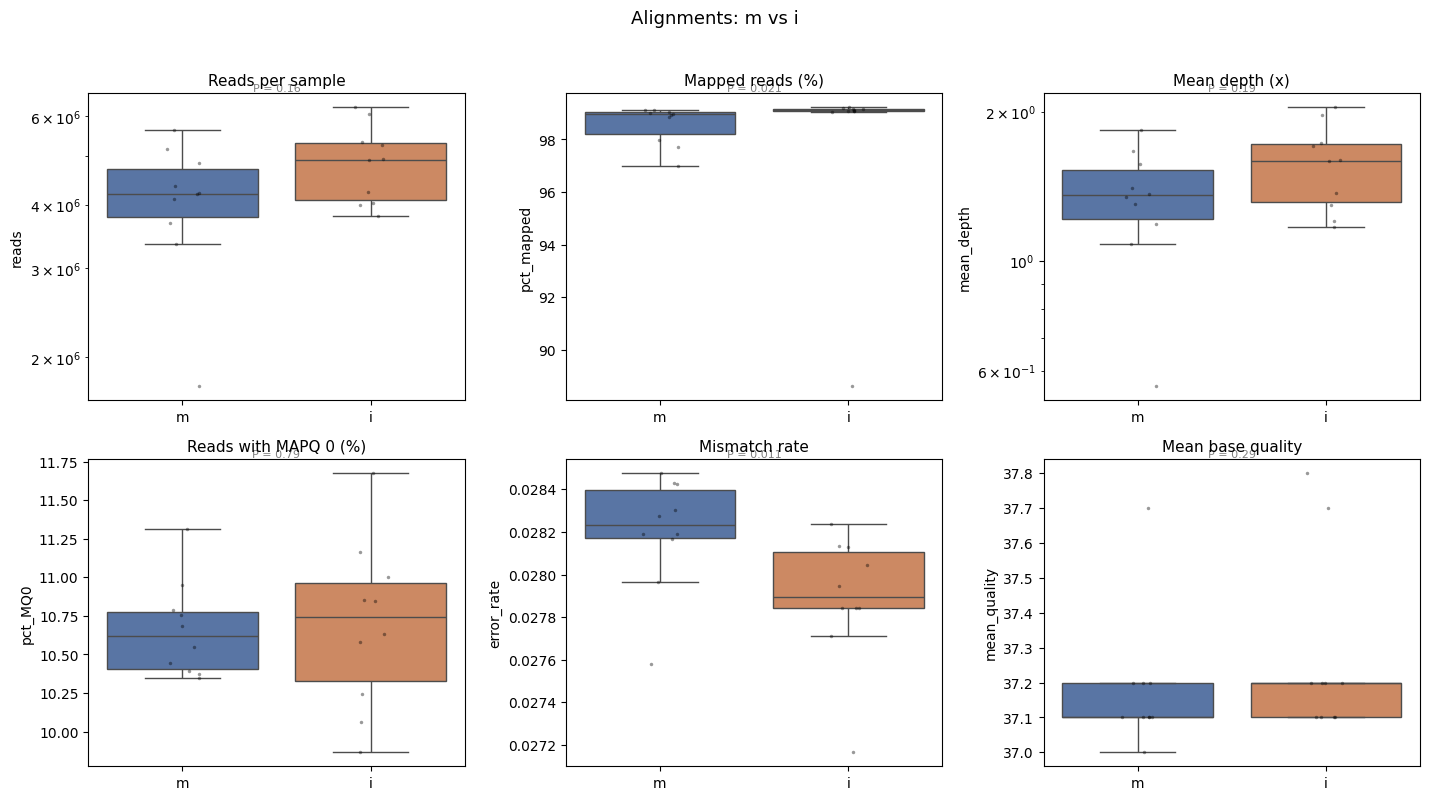

,metric,median_m,median_i,mannwhitney_P
0,Reads per sample,4.209507e+06,4.918808e+06,0.161972
1,Mapped reads (%),9.895549e+01,9.910256e+01,0.021134
2,Mean depth (x),1.355634e+00,1.593309e+00,0.185877
3,Reads with MAPQ 0 (%),1.061856e+01,1.074086e+01,0.791337
4,Mismatch rate,2.823242e-02,2.789461e-02,0.011330
5,Mean base quality,3.710000e+01,3.720000e+01,0.291222


In [31]:
metrics = {"reads": "Reads per sample", "pct_mapped": "Mapped reads (%)", "mean_depth": "Mean depth (x)",
           "pct_MQ0": "Reads with MAPQ 0 (%)", "error_rate": "Mismatch rate", "mean_quality": "Mean base quality"}
stats_aln = compare_morphs(aln, metrics, ncols=3, logy=("reads", "mean_depth"), title="Alignments: m vs i")
display(stats_aln)

### 11.3 Sex-chromosome check

All individuals in this dataset are **females**, and in Lepidoptera females are the heterogametic sex (**ZW**), males are ZZ. A female carries **one** copy of the Z, so reads from the Z chromosome should map at **about half the depth of the autosomes**. The paper confirms this expectation for the mother of the sequenced trio. This gives a free, independent check: a sample whose Z depth is close to the autosomal depth might be a **male** (ZZ), a mislabelled sample, or a sample mix-up.

We compute, for every sample, the **read density** (reads per base) of the Z chromosome divided by the median read density of the autosomes.

In [32]:
def read_idxstats(path):
    t = pd.read_csv(path, sep="\t", header=None, names=["contig", "length", "mapped", "unmapped"])
    return t[t.contig != "*"].set_index("contig")["mapped"]

idx = pd.DataFrame({s: read_idxstats(DIRS["qc_aln"] / f"{s}.idxstats") for s in samples})
dens = idx.div(fai.set_index("contig").length, axis=0)          # reads per base

if Z_CHROM is not None:
    autos = fai[(fai.length > 5e6) & fai.label.fillna("").str.fullmatch(r"\d+") & (fai.contig != Z_CHROM)].contig
    autos = [c for c in autos if c in dens.index]
    aln["Z_to_autosome_ratio"] = (dens.loc[Z_CHROM] / dens.loc[autos].median()).reindex(aln.sampleID).values
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.boxplot(data=aln, x="morph", y="Z_to_autosome_ratio", order=MORPH_ORDER, hue="morph",
                palette=MORPH_COLORS, showfliers=False, ax=ax, legend=False)
    sns.stripplot(data=aln, x="morph", y="Z_to_autosome_ratio", order=MORPH_ORDER, color="k", size=2.5, alpha=0.4, ax=ax)
    ax.axhline(0.5, ls="--", c="grey"); ax.axhline(1.0, ls=":", c="grey")
    ax.set(ylabel="Z read density / autosome read density", xlabel="",
           title=f"Females (ZW) should be near 0.5 (dashed)\n{len(autos)} autosomes used")
    plt.tight_layout(); plt.show()
    print("Median ratio:", round(aln.Z_to_autosome_ratio.median(), 2))
    print("At very low depth this ratio is noisy for individual samples; the median is the informative number.")
else:
    print("Z chromosome not identified (Z_CHROM is None): skipping the sex check.")

Z chromosome not identified (Z_CHROM is None): skipping the sex check.


### 11.4 Alignment report with MultiQC (optional)

The file `QC_alignment/multiqc_alignment.html` was created in Section 11 and combines `flagstat`, `stats` and `idxstats` for every sample. Download it as before if you want to explore it interactively.

In [33]:
if DOWNLOAD_REPORTS:
    from google.colab import files
    files.download(str(DIRS["qc_aln"] / "multiqc_alignment.html"))
else:
    print("Report is on Drive:", DIRS["qc_aln"] / "multiqc_alignment.html")

Report is on Drive: /content/drive/MyDrive/GWAS/QC_alignment/multiqc_alignment.html


## 12. Positive Control: Read Depth at the M Locus

Recall from Section 0.2 that the reference was assembled from an **M homozygote** and contains two TE insertions (2.4 kb and 4.3 kb) in the dominant allele, **inside the 6,731,000-6,743,400 window on chromosome 26**. Reads from **`mm` (inaria) individuals do not contain these insertions**, so they cannot map there. Therefore:

* in the `i` samples (genotype `mm`) the depth should **fall to near zero** over the inserted tracts;
* in the `m` samples (genotype `M-`) the depth should be more even, with a partial reduction in heterozygotes (`Mm`).

This is exactly the pattern the authors used (their Fig. 3E) to spot the insertions: no depth, no genotypes, so the SNP association drops between the three association peaks.

We compute, for each sample, the depth in 25 kb around the locus, **normalise it by that sample's genome-wide mean depth** (so that deeply and shallowly sequenced samples are comparable), pool the samples of each morph, and plot the average in 250 bp bins.

> **Expectation management.** Our FASTQ files are *small* subsets, and each individual has well below 1x coverage. The signal is therefore noisy, and may be weak or invisible if the subsets are tiny or were not drawn from this region. Seeing the dip is a nice confirmation that morphs, files, reference and coordinates are all consistent; *not* seeing it is not necessarily a problem with the pipeline.

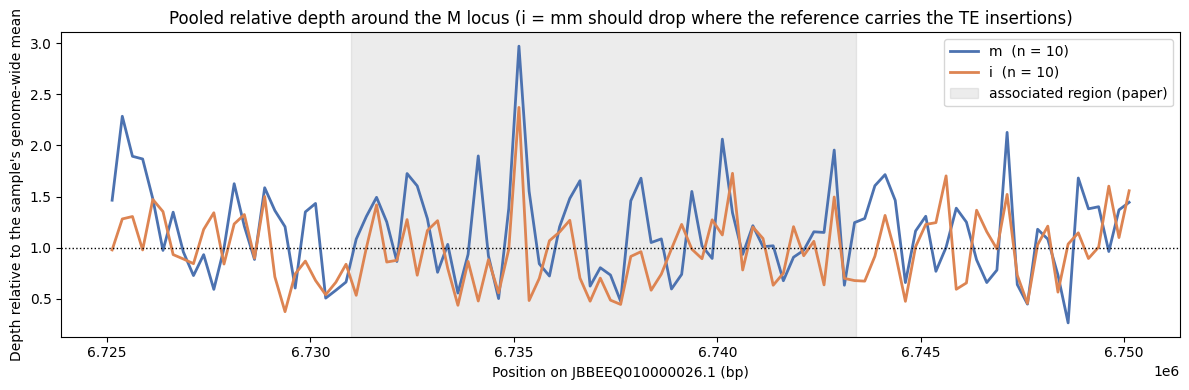

In [34]:
import matplotlib.patches as mpatches

REGION_START, REGION_END = 6_725_000, 6_750_000      # window to plot
PEAK_START, PEAK_END = 6_731_000, 6_743_400          # associated region reported in the paper
BIN = 250

if M_CHROM is None:
    print("M_CHROM is not defined (see Section 9.6): skipping.")
else:
    bam_list = SCRATCH / "bam_list_ordered.txt"
    bam_list.write_text("\n".join(str(DIRS["bams"] / f"{s}.sorted.bam") for s in samples) + "\n")
    res = subprocess.run(["samtools", "depth", "-a", "-r", f"{M_CHROM}:{REGION_START}-{REGION_END}",
                          "-f", str(bam_list)], capture_output=True, text=True)
    assert res.returncode == 0, res.stderr
    d = pd.read_csv(io.StringIO(res.stdout), sep="\t", header=None)
    pos = d[1].values
    depth = d.iloc[:, 2:].values.astype(float)                    # positions x samples
    rel = depth / aln.set_index("sampleID").loc[samples, "mean_depth"].replace(0, np.nan).values   # normalised by genome-wide mean

    bins = (pos - REGION_START) // BIN
    fig, ax = plt.subplots(figsize=(12, 4))
    for m_ in MORPH_ORDER:
        cols_ = np.where(sheet.morph.values == m_)[0]
        per_bin = pd.Series(rel[:, cols_].mean(axis=1)).groupby(bins).mean()
        ax.plot(REGION_START + per_bin.index * BIN + BIN / 2, per_bin.values, color=MORPH_COLORS[m_],
                lw=2, label=f"{m_}  (n = {len(cols_)})")
    ax.axvspan(PEAK_START, PEAK_END, color="grey", alpha=0.15, label="associated region (paper)")
    ax.axhline(1, c="k", ls=":", lw=1)
    ax.set(xlabel=f"Position on {M_CHROM} (bp)", ylabel="Depth relative to the sample's genome-wide mean",
           title="Pooled relative depth around the M locus (i = mm should drop where the reference carries the TE insertions)")
    ax.legend(); plt.tight_layout(); plt.show()

## 13. Hand-off Files for the Association Notebook

The next notebook will test for association between the **`m`** and **`i`** morphs. To make that easy we write a few small files, all listing samples in **the same order**:

| File | Content |
|---|---|
| `alignment_summary.tsv` | per-sample QC metrics from Section 11 (already written) |
| `bam_list.txt` | one BAM path per line; the format ANGSD and bcftools expect |
| `bam_list_m.txt`, `bam_list_i.txt` | the same, split by morph |
| `phenotypes.tsv` | sample ID, morph, **binary phenotype** (`m` = 1, `i` = 0, as coded in the paper: *misippus* = 1, *inaria* = 0), BAM path, depth and outlier flags |

> We deliberately **do not drop** flagged samples here: whether to exclude low-yield samples or use depth as a covariate is a decision for the association step, informed by the comparisons above.

In [35]:
pheno = (sheet[["sampleID", "morph"]]
         .assign(phenotype=lambda x: (x.morph == "m").astype(int),
                 bam=lambda x: x.sampleID.map(lambda s: str(DIRS["bams"] / f"{s}.sorted.bam")))
         .merge(aln[["sampleID", "reads", "pct_mapped", "mean_depth", "flag_low_yield", "flag_low_mapping"]], on="sampleID"))

missing = [b for b in pheno.bam if not Path(b).exists()]
assert not missing, f"{len(missing)} BAM files are missing, e.g. {missing[:3]}"

pheno.to_csv(PROJECT_DIR / "phenotypes.tsv", sep="\t", index=False)
(PROJECT_DIR / "bam_list.txt").write_text("\n".join(pheno.bam) + "\n")
(PROJECT_DIR / "bam_list_m.txt").write_text("\n".join(pheno.bam[pheno.morph == "m"]) + "\n")
(PROJECT_DIR / "bam_list_i.txt").write_text("\n".join(pheno.bam[pheno.morph == "i"]) + "\n")

print(f"{len(pheno)} samples written: {(pheno.morph == 'm').sum()} m (phenotype 1) and {(pheno.morph == 'i').sum()} i (phenotype 0)")
print("Files in", PROJECT_DIR)
for f in ["sample_sheet.tsv", "alignment_summary.tsv", "phenotypes.tsv", "bam_list.txt", "bam_list_m.txt", "bam_list_i.txt"]:
    print("  ", f)
display(pheno.head())

20 samples written: 10 m (phenotype 1) and 10 i (phenotype 0)
Files in /content/drive/MyDrive/GWAS
   sample_sheet.tsv
   alignment_summary.tsv
   phenotypes.tsv
   bam_list.txt
   bam_list_m.txt
   bam_list_i.txt


,sampleID,morph,phenotype,bam,reads,pct_mapped,mean_depth,flag_low_yield,flag_low_mapping
0,CAM035143,m,1,/content/drive/MyDrive/GWAS/bams/CAM035143.sor...,3343685.0,99.000624,1.080211,False,False
1,CAM035144,m,1,/content/drive/MyDrive/GWAS/bams/CAM035144.sor...,4843707.0,99.133969,1.566253,False,False
2,CAM035145,m,1,/content/drive/MyDrive/GWAS/bams/CAM035145.sor...,4109374.0,96.996404,1.302357,False,True
3,CAM035146,m,1,/content/drive/MyDrive/GWAS/bams/CAM035146.sor...,4200777.0,99.114902,1.363506,False,False
4,CAM035147,m,1,/content/drive/MyDrive/GWAS/bams/CAM035147.sor...,4218237.0,97.715467,1.347762,False,True


## 14. Summary

In this notebook we:

✅ Installed **Conda** and **FastQC, MultiQC, fastp, seqkit, BWA, SAMtools and BEDTools** in Google Colab.  
✅ Mounted **Google Drive**, located `smallfastqs_Hypolimnas_misippus` and the metadata files, and built a **sample sheet** that links every FASTQ file to a `CAM` sample ID and to its **morph** (`m` / `i`).  
✅ Summarised the raw reads with **seqkit**, ran **FastQC / MultiQC** (`QC_before_adapter_removal/`), and compared the two morphs.  
✅ Trimmed adapters and poor-quality bases with **fastp** (`trimmed_fastqs/`) and verified the result with a second **FastQC / MultiQC** round (`QC_after_adapter_removal/`).  
✅ **Downloaded the *H. misippus* HypMis_v2 reference from NCBI on the fly**, checked its checksum and statistics against the paper, and built the BWA and SAMtools indexes (`reference_HypMis_v2/`).  
✅ Aligned every sample with **BWA-MEM**, with the **CAM ID as read-group sample name**, producing sorted, indexed BAM files (`bams/`).  
✅ Evaluated mapping rate, depth, error rate, a **ZW sex-chromosome check**, and tested for **technical differences between morphs**.  
✅ Looked at read depth around the **M locus** on chromosome 26 as a positive control.  
✅ Wrote `phenotypes.tsv` and BAM lists for the association notebook.

### Take-home messages

* **Always keep track of which file is which sample.** The sample sheet and the read-group `SM` tag make sure that BAM files can be matched with phenotypes without relying on file names.
* **QC is a comparison between groups, not only between samples.** A technical difference between `m` and `i` samples is a potential confounder in the association test.
* **At low coverage, depth and mapping quality set the limits of what can be genotyped.** The M locus is a good example: where the reference carries a TE insertion that `mm` individuals lack, there are no reads and so no genotypes.

### Next steps

* Compute **genotype likelihoods** (for example with ANGSD) or call and impute variants from the BAM files listed in `bam_list.txt`.
* Check **population structure** with PCA before testing association (the paper found no structure along chromosome 26).
* Run the **association test between `m` and `i`**, optionally with depth as a covariate, and visualise the result with a Manhattan plot. If everything went well, the strongest signal should be on **chromosome 26 near 6.73 Mb**.

### References

* Orteu A, Kucka M, Gordon IJ, et al. (2024). *Transposable element insertions are associated with Batesian mimicry in the pantropical butterfly Hypolimnas misippus.* Mol Biol Evol 41(3): msae041. (ENA project PRJEB64669)
* Orteu A, McCarthy SA, Hornett EA, et al. (2024). *The Hypolimnas misippus genome supports a common origin of the W chromosome in Lepidoptera.* Genome Biol Evol 16(10): evae215. (NCBI BioProject PRJNA1086912)
* Meier JI, Salazar PA, Kučka M, et al. (2021). *Haplotype tagging reveals parallel formation of hybrid races in two butterfly species.* PNAS 118(25): e2015005118. (haplotagging)
* Andrews S. (2010). *FastQC: a quality control tool for high throughput sequence data.*
* Ewels P, Magnusson M, Lundin S, Käller M. (2016). *MultiQC: summarize analysis results for multiple tools and samples in a single report.* Bioinformatics 32: 3047-3048.
* Chen S, Zhou Y, Chen Y, Gu J. (2018). *fastp: an ultra-fast all-in-one FASTQ preprocessor.* Bioinformatics 34: i884-i890.
* Shen W, Le S, Li Y, Hu F. (2016). *SeqKit: a cross-platform and ultrafast toolkit for FASTA/Q file manipulation.* PLoS ONE 11: e0163962.
* Li H. (2013). *Aligning sequence reads, clone sequences and assembly contigs with BWA-MEM.* arXiv:1303.3997.
* Danecek P, Bonfield JK, Liddle J, et al. (2021). *Twelve years of SAMtools and BCFtools.* GigaScience 10: giab008.

In [36]:
!jupyter nbconvert --to html /content/drive/MyDrive/GWAS/QC_Alignment_Hypolimnas_misippus_Colab.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/GWAS/QC_Alignment_Hypolimnas_misippus_Colab.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 1128013 bytes to /content/drive/MyDrive/GWAS/QC_Alignment_Hypolimnas_misippus_Colab.html
